# India Tech Job Market & Hiring Intelligence — 2026 

**Business objective:
Analyze India's technology job market to identify hiring hotspots, high-demand roles, company hiring patterns, experience requirements, 
and opportunities for candidates and workforce-planning teams.**


**1. Business Objective**

**2. Dataset Overview**

**2.1 Data Loading**

**2.2 Dataset Structure**

**3. Data Quality & Cleaning**

**3.1 Missing Values**

**3.2 Duplicate Records**

**3.3 Data Types**

**3.4 Role Classification Quality**

**3.5 Experience Data Quality**

**3.6 Location Standardization**

**3.7 Job Title Standardization**

**4. Exploratory Data Analysis**

**4.1 Role Distribution**

**4.2 Company Hiring Volume**

**4.3 Experience Requirements**

**4.4 Geographic Hiring Patterns**

**4.5 Role × Location**

**4.6 Company × Role**

**4.7 Work Mode Analysis**

**4.8 Work Mode × Role**

**4.9 Company Role Diversity**

**4.10 Hiring Volume vs Specialization**

**5. Final Business Insights**

**6. Business Recommendations**

**7. Limitations**

**8. Conclusion**

## 🚀 Step 1: Data Understanding

In [181]:
import pandas as pd 

**I use Pandas because it provides efficient data structures such as DataFrame and Series and provides functions for data cleaning, transformation, aggregation, and analysis.**

In [184]:
df=pd.read_csv(r"C:\Users\husan\Downloads\indian_tech_jobs_2026-selected-columns.csv")

In [186]:
df.head()

,job_id,job_title,company_name,company_rating,location,scraped_city,role_category,experience_raw,experience_min_yrs,experience_max_yrs
0,1,Data Scientist,Cisco,4.1,Bengaluru,Bangalore,Data Scientist,7-10 Yrs,7.0,10.0
1,2,Data Scientist,Caterpillar Inc,4.1,Bengaluru,Bangalore,Data Scientist,4-8 Yrs,4.0,8.0
2,3,Analytics Data Scientist,Foreign IT Consulting MNC,3.6,"Hyderabad, Chennai, Bengaluru",Bangalore,Data Scientist,4-9 Yrs,4.0,9.0
3,4,Data Scientist,Fortune 500 IT Services Company,3.6,"Mumbai, Bengaluru",Bangalore,Data Scientist,10-14 Yrs,0.0,0.0
4,5,Sr. Artificial Intelligence Engineer,Fortune 500 Product-based MNC,3.6,"Pune, Bengaluru",Bangalore,Data Scientist,5-10 Yrs,5.0,10.0


**head() displays the first 5 rows by default.**

In [189]:
df.shape

(23201, 10)

**My dataset contains 23,201 technology job postings and 10 attributes describing job, company, location, role, and experience information.**

In [192]:
df.columns

Index(['job_id', 'job_title', 'company_name', 'company_rating', 'location',
       'scraped_city', 'role_category', 'experience_raw', 'experience_min_yrs',
       'experience_max_yrs'],
      dtype='object')

**I inspect the column names to understand what dimensions and measures are available for analysis and to identify which variables may be relevant to the business questions.**

In [195]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23201 entries, 0 to 23200
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   job_id              23201 non-null  int64  
 1   job_title           23201 non-null  object 
 2   company_name        23201 non-null  object 
 3   company_rating      23201 non-null  float64
 4   location            23201 non-null  object 
 5   scraped_city        23201 non-null  object 
 6   role_category       23201 non-null  object 
 7   experience_raw      23201 non-null  object 
 8   experience_min_yrs  23201 non-null  float64
 9   experience_max_yrs  23201 non-null  float64
dtypes: float64(3), int64(1), object(6)
memory usage: 1.8+ MB


**I use info() to understand the schema of the dataset, check data types, and identify columns with missing values by comparing the non-null count with the total number of records.
info() tells us information about the dataset.**

In [198]:
df.describe()

,job_id,company_rating,experience_min_yrs,experience_max_yrs
count,23201.000000,23201.000000,23201.000000,23201.000000
mean,11601.000000,3.586449,4.135080,7.829059
std,6697.696134,0.514250,2.933976,3.946834
min,1.000000,1.000000,0.000000,0.000000
25%,5801.000000,3.400000,2.000000,5.000000
50%,11601.000000,3.600000,4.000000,8.000000
75%,17401.000000,3.800000,6.000000,10.000000
max,23201.000000,5.000000,25.000000,31.000000


**describe() provides descriptive statistics for numerical columns, including count, mean, standard deviation, minimum, quartiles, and maximum. It helps me understand the central tendency, spread, and potential unusual values in the data.**

In [201]:
df.nunique()

job_id                23201
job_title             13128
company_name           6993
company_rating           41
location               1565
scraped_city             11
role_category             6
experience_raw          238
experience_min_yrs       23
experience_max_yrs       29
dtype: int64

**This tells us how many unique values each column contains.**

## 🔍 Step 2 — Data Quality Audit

## 🔎 Finding — Missing Values
    

In [206]:
df.isnull().sum()

job_id                0
job_title             0
company_name          0
company_rating        0
location              0
scraped_city          0
role_category         0
experience_raw        0
experience_min_yrs    0
experience_max_yrs    0
dtype: int64

**No missing values were found in any column of the dataset. All 10 variables contain complete records, so no missing-value treatment is required at this stage.**

## 🔎 Duplicate Record Analysis

In [210]:
df.duplicated().sum()

np.int64(0)

**📊 Since duplicate rows are not present, our hiring-volume analysis will not be artificially inflated because of exact duplicate records.**

## 🔐 Job ID Uniqueness Analysis

In [214]:
df["job_id"].duplicated().sum()

np.int64(0)

**📊 Duplicate job_ids: 0**

**💡 
Each record in the dataset is associated with a unique job_id, confirming that job_id can be used as a unique identifier for individual job postings.**

# 🧪 Data Type Validation

In [219]:
df.dtypes

job_id                  int64
job_title              object
company_name           object
company_rating        float64
location               object
scraped_city           object
role_category          object
experience_raw         object
experience_min_yrs    float64
experience_max_yrs    float64
dtype: object

**📊 This code checks the data type of every column in the dataset. The output shows that numerical variables such as company_rating, experience_min_yrs, and experience_max_yrs are stored as numeric (float64), while descriptive variables such as job_title, company_name, location, scraped_city, and role_category are stored as object (text). experience_raw is also stored as text because it contains the original experience representation. Overall, the columns have suitable data types for our planned analysis, so no major datatype conversion is required at this stage.**

# 🔎 Role Category Consistency

In [223]:
df["role_category"].unique()

array(['Data Scientist', 'Data Analyst', 'Machine Learning Engineer',
       'Data Engineer', 'Business Analyst', 'Python Developer'],
      dtype=object)

**📊 This code identifies all the unique categories present in the role_category column. The dataset contains 6 distinct technology roles: Data Scientist, Data Analyst, Machine Learning Engineer, Data Engineer, Business Analyst, and Python Developer. The categories are consistently formatted, with no obvious duplicate variations such as different capitalization or spelling of the same role. Therefore, role_category is ready for categorical analysis and comparison across roles.**

# 📊 Role Demand Distribution

In [227]:
df["role_category"].value_counts()

role_category
Data Scientist               6455
Data Analyst                 4729
Business Analyst             4505
Machine Learning Engineer    4004
Data Engineer                1922
Python Developer             1586
Name: count, dtype: int64

**📊This code counts the number of job postings available for each role_category. The results show that Data Scientist has the highest number of postings with 6,455 jobs, followed by Data Analyst (4,729) and Business Analyst (4,505). Machine Learning Engineer accounts for 4,004 postings, while Data Engineer (1,922) and Python Developer (1,586) have comparatively lower representation. Overall, the dataset shows stronger hiring demand for data-focused and analytical roles, with Data Scientist being the most represented role.**

**🔎 Key Observation**

**Data Scientist → highest demand**

**Python Developer → lowest demand**

# 📈 Convert Counts into Percentages

In [232]:
role_percentage=(df["role_category"].value_counts()/len(df))*100
role_percentage

role_category
Data Scientist               27.822077
Data Analyst                 20.382742
Business Analyst             19.417266
Machine Learning Engineer    17.257877
Data Engineer                 8.284126
Python Developer              6.835912
Name: count, dtype: float64

**📊 This code converts the number of job postings for each role into a percentage of the total 23,201 job postings. This makes the comparison easier because we can understand the relative contribution of each role to the overall hiring dataset. Data Scientist accounts for 27.82% of all postings, making it the largest category. Data Analyst contributes 20.38%, followed by Business Analyst at 19.42% and Machine Learning Engineer at 17.26%. Data Engineer and Python Developer represent smaller shares of 8.28% and 6.84%, respectively.**

**🏢 Business Meaning**

**The top four categories—Data Scientist, Data Analyst, Business Analyst, and Machine Learning Engineer—together account for approximately 84.9% of all postings in the dataset. This indicates that the dataset is heavily concentrated around data, analytics, and machine-learning-oriented roles.**

# 📈 Now Let's Visualize It

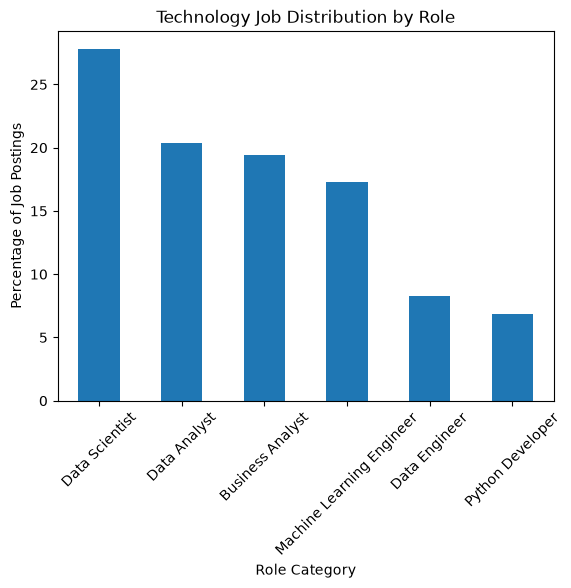

In [237]:
import matplotlib.pyplot as plt

role_percentage.plot(kind="bar")

plt.title("Technology Job Distribution by Role")
plt.xlabel("Role Category")
plt.ylabel("Percentage of Job Postings")
plt.xticks(rotation=45)
plt.show()

**📊 
The visualization confirms the earlier numerical analysis. Data Scientist has the highest share of job postings at 27.82%, followed by Data Analyst at 20.38%, Business Analyst at 19.42%, and Machine Learning Engineer at 17.26%. Data Engineer and Python Developer have considerably smaller shares. The chart makes the concentration of job postings toward data and analytics-oriented roles immediately visible.**

**🔎 Key Insight**

**Data Scientist alone represents more than one-fourth of all job postings in the dataset, while the four largest role categories collectively represent approximately 84.9% of postings.**

**🏢 Business Meaning**

**The hiring landscape represented by this dataset is strongly concentrated around data, analytics, and AI/ML capabilities. This could indicate that organizations are increasingly recruiting for roles that support data-driven decision-making and intelligent systems.**

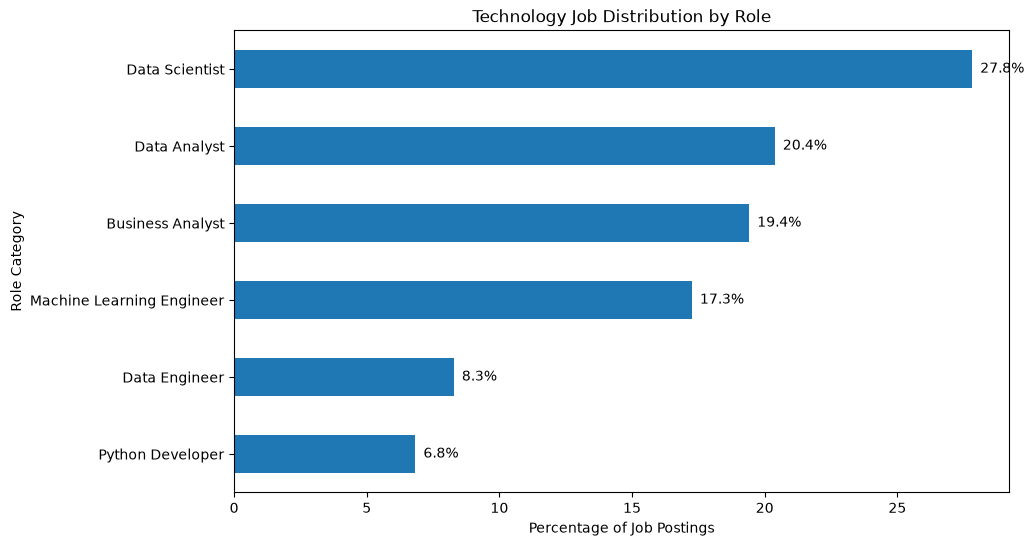

In [240]:
role_percentage = role_percentage.sort_values()

ax = role_percentage.plot(kind="barh", figsize=(10, 6))

plt.title("Technology Job Distribution by Role")
plt.xlabel("Percentage of Job Postings")
plt.ylabel("Role Category")

for i, value in enumerate(role_percentage):
    ax.text(value + 0.3, i, f"{value:.1f}%", va="center")

plt.show()

# 🏢 Company Hiring Analysis

In [242]:
df["company_name"].value_counts().head(10)

company_name
Tata Consultancy Services    653
Accenture                    438
EY                           340
Leading Client               243
Infosys                      209
Capgemini                    195
Photon                       193
Logic Planet                 185
Hexaware Technologies        147
Sparix Global                126
Name: count, dtype: int64

**🏢 Business Meaning**

**TCS, Accenture, and EY emerge as the strongest individual hiring contributors in this dataset. However, because the top 10 companies account for only about 11.8% of all postings, the overall hiring market appears relatively fragmented across many employers.**

# 📈 Visualize Top Hiring Companies

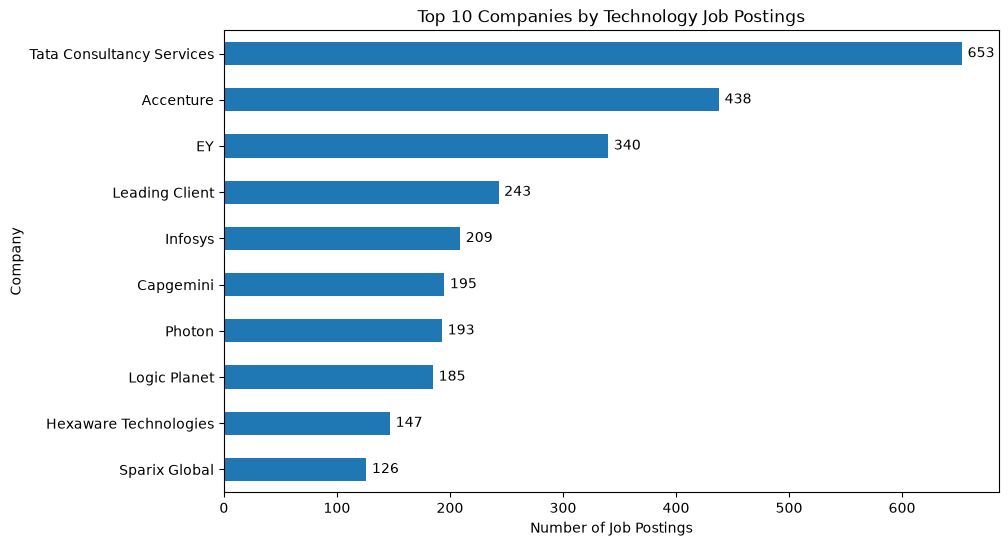

In [248]:
top_companies = df["company_name"].value_counts().head(10)

ax = top_companies.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Companies by Technology Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Company")

for i, value in enumerate(top_companies.sort_values()):
    ax.text(value + 5, i, str(value), va="center")

plt.show()

**📊 
This visualization ranks the top 10 companies based on the number of technology job postings in the dataset. Tata Consultancy Services leads with 653 postings, followed by Accenture with 438 and EY with 340. There is a noticeable gap between TCS and the other companies, indicating that TCS has the highest hiring representation among the companies captured in this dataset. The remaining companies show comparatively lower but still significant posting volumes.**

**🔎 Key Insight
TCS has approximately 49% more job postings than Accenture, making it the strongest individual hiring contributor among the top 10 companies.**

In [252]:
df[df["company_name"]=="Leading Client"].head(10)

,job_id,job_title,company_name,company_rating,location,scraped_city,role_category,experience_raw,experience_min_yrs,experience_max_yrs
91,92,Data Scientist,Leading Client,3.6,Bengaluru,Bangalore,Data Scientist,7-12 Yrs,7.0,12.0
92,93,Data Scientist,Leading Client,3.6,"Noida, Hyderabad, Bengaluru",Bangalore,Data Scientist,4-9 Yrs,4.0,9.0
178,179,Data Scientist,Leading Client,3.6,"Chennai, Bengaluru",Bangalore,Data Scientist,5-10 Yrs,5.0,10.0
547,548,Manager - Data Scientist,Leading Client,3.6,Bengaluru,Bangalore,Data Scientist,4-9 Yrs,4.0,9.0
669,670,Senior Data Analyst,Leading Client,3.6,Bengaluru,Bangalore,Data Scientist,3-8 Yrs,3.0,8.0
940,941,Senior Snowflake Cortex Data Scientist,Leading Client,3.6,Mumbai,Mumbai,Data Scientist,4-8 Yrs,4.0,8.0
1087,1088,"Data Engineer - ( Snowflake, AWS, Python)",Leading Client,3.6,"Mumbai, Hyderabad, Bengaluru",Mumbai,Data Scientist,5-8 Yrs,5.0,8.0
1106,1107,Analyst Data Governance,Leading Client,3.6,Navi Mumbai,Mumbai,Data Scientist,4-9 Yrs,4.0,9.0
1117,1118,Analyst Data Governance,Leading Client,3.6,Mumbai,Mumbai,Data Scientist,4-9 Yrs,4.0,9.0
1121,1122,Petrophysics Data Analyst-G&G Ops Specialist 5...,Leading Client,3.6,Hybrid - Mumbai,Mumbai,Data Scientist,5-10 Yrs,5.0,10.0


**📊
This code filters the dataset to inspect records where the company_name is "Leading Client". The results show that this value is being used repeatedly as the company name, with a company rating of 3.6, while the actual job titles and locations vary considerably. For example, the records include Data Scientist, Senior Data Analyst, Data Engineer, and Data Governance positions across Bengaluru, Mumbai, Hyderabad, Chennai, and Noida. This suggests that "Leading Client" is a generic/anonymized company label rather than a specific identifiable employer name.**

# 🔎 Role Classification Consistency

In [256]:
pd.crosstab(df["role_category"],df["job_title"]).head()

job_title,.NET & Angular Full-Stack Developer | Enterprise Web Applications,.NET (flutter developer),.NET Application Developer,.NET Application Developer (Azure),.NET Application Developer (React + AI Tools),.NET Full Stack Developer / Senior Software Engineer,".NET Full Stack Developer-ASP.NET Core,Angular/React,Cloud Integration",.NET Intern,.NET REACT Developer,.NET Software Developer,...,python developer,python developer-Immediate joiner-Bangalore /Chennai,sales executive,salesforce experience cloud developer,sap hybris business analyst,senir business analyst IT,seo-executive,sr. data scientist,windchill Business Analyst,zoho developer
role_category,,,,,,,,,,,,,,,,,,,,,
Business Analyst,0,0,1,0,0,0,0,1,0,3,...,0,0,0,1,1,1,0,0,0,0
Data Analyst,0,0,0,0,0,0,0,0,0,1,...,0,0,1,0,0,0,1,0,0,1
Data Engineer,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Data Scientist,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,1,0
Machine Learning Engineer,0,0,1,0,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [257]:
df.groupby("role_category")["job_title"].value_counts().groupby(level=0).head(5)

role_category              job_title                       
Business Analyst           Business Analyst                    500
                           Senior Business Analyst             101
                           Salesforce Business Analyst          29
                           Technical Business Analyst           20
                           Business Consultants                 19
Data Analyst               Data Analyst                        155
                           Business Analyst                    118
                           Senior Data Analyst                  60
                           Executive                            34
                           MIS Executive                        34
Data Engineer              Data Engineer                       311
                           Azure Data Engineer                  35
                           Gcp Data Engineer                    23
                           Senior Data Engineer                 23
  

**📊 
This code groups job titles according to their assigned role_category and returns the five most frequent job titles within each category. It helps us evaluate whether the assigned role categories logically match the actual job titles.**

**🏢 
If we use role_category directly for hiring-demand analysis, some role counts may be misclassified, which could lead to misleading conclusions about demand for Data Scientist, Data Engineer, Data Analyst, and other roles.**

# 🧪 Measure Potential Misclassification

# 🚨Data Engineer Classification Analysis

In [264]:
df[
    df["job_title"].str.contains("Data Engineer", case=False, na=False)
]["role_category"].value_counts()

role_category
Data Scientist               2237
Data Engineer                 836
Machine Learning Engineer     176
Data Analyst                   81
Python Developer                2
Name: count, dtype: int64

**📊 The result shows that 2,237 Data Engineer-related job titles are classified as Data Scientist, while only 836 are classified as Data Engineer. Smaller numbers are classified as Machine Learning Engineer (176), Data Analyst (81), and Python Developer (2). This indicates a substantial mismatch between the actual job title and the assigned role category.**

**🔎 Key Finding**

**There are:**

**3,332 job titles containing "Data Engineer".**

**But only:**

**836 → Data Engineer**

**while:**

**2,237 → Data Scientist**

**So approximately 67.1% of these Data Engineer-related titles are categorized as Data Scientist.**



# 🔍 Measure Role Classification Consistency

In [269]:
roles = [
    "Data Scientist",
    "Data Analyst",
    "Data Engineer",
    "Business Analyst",
    "Machine Learning Engineer",
    "Python Developer"
]

results = []

for role in roles:
    mask = df["job_title"].str.contains(role, case=False, na=False)
    
    total = mask.sum()
    correct = (df.loc[mask, "role_category"] == role).sum()
    mismatch = total - correct
    
    results.append([
        role,
        total,
        correct,
        mismatch,
        round((mismatch / total) * 100, 2)
    ])

consistency_df = pd.DataFrame(
    results,
    columns=[
        "Role",
        "Title Matches",
        "Category Matches",
        "Potential Mismatches",
        "Mismatch %"
    ]
)

consistency_df

,Role,Title Matches,Category Matches,Potential Mismatches,Mismatch %
0,Data Scientist,1593,1563,30,1.88
1,Data Analyst,1125,659,466,41.42
2,Data Engineer,3332,836,2496,74.91
3,Business Analyst,2680,1875,805,30.04
4,Machine Learning Engineer,425,349,76,17.88
5,Python Developer,563,481,82,14.56


**📊 Explanation & Insight**

**The results show a major classification inconsistency in the dataset.**

**🟢 Data Scientist: only 1.88% potential mismatch → very consistent.**

**🟡 Python Developer: 14.56% potential mismatch.**

**🟡 Machine Learning Engineer: 17.88% potential mismatch.**

**🟠 Business Analyst: 30.04% potential mismatch.**

**🔴 Data Analyst: 41.42% potential mismatch.**

**🔴 Data Engineer: 74.91% potential mismatch → largest issue.**

**The biggest finding is Data Engineer:**

**Out of 3,332 postings whose title contains "Data Engineer", only 836 are categorized as Data Engineer, while 2,496 are assigned to another category.**

**🔎 Key Finding**

**role_category should not yet be treated as ground truth for role-demand analysis.**

In [273]:
df[(df["job_title"].str.contains("Data Engineer",case=False,na=False))&
(df["role_category"]!="Data Engineer")
]["job_title"].value_counts().head(15)

job_title
Data Engineer                 536
Senior Data Engineer          222
Azure Data Engineer           124
Lead Data Engineer             55
Gcp Data Engineer              42
Big Data Engineer              39
GCP Data Engineer              34
Aws Data Engineer              31
Snowflake Data Engineer        29
Sr. Data Engineer              23
Cloud Data Engineer            17
AWS Data Engineer              15
Sr Data Engineer               15
Senior Azure Data Engineer     12
AI Data Engineer               12
Name: count, dtype: int64

**📊 The important point is that the mismatch isn't mainly because of unusual titles.**

**Even very direct titles such as:**

**Data Engineer, Senior Data Engineer, Azure Data Engineer, Lead Data Engineer are appearing under another category.**

**That strongly suggests that the categorization logic/source labeling is inconsistent, particularly for Data Engineer roles.**

# 🔎 company_rating quality check

In [277]:
df["company_rating"].describe()

count    23201.000000
mean         3.586449
std          0.514250
min          1.000000
25%          3.400000
50%          3.600000
75%          3.800000
max          5.000000
Name: company_rating, dtype: float64

In [279]:
df["company_rating"].unique()

array([4.1, 3.6, 3.7, 4.4, 3.8, 4. , 3.9, 3.4, 2.8, 3.5, 3.3, 2.4, 4.9,
       2.1, 4.2, 4.6, 3.1, 3. , 2.7, 4.3, 2.6, 4.5, 2.9, 2.5, 3.2, 4.7,
       2. , 5. , 1.9, 4.8, 2.3, 1.8, 1. , 2.2, 1.6, 1.7, 1.2, 1.1, 1.5,
       1.3, 1.4])

**🔎 Key Finding**

**Company ratings range from 1.0 to 5.0, with an average rating of 3.59. No obvious out-of-range ratings were identified.**

In [282]:
df[["experience_min_yrs","experience_max_yrs"]].describe()

,experience_min_yrs,experience_max_yrs
count,23201.000000,23201.000000
mean,4.135080,7.829059
std,2.933976,3.946834
min,0.000000,0.000000
25%,2.000000,5.000000
50%,4.000000,8.000000
75%,6.000000,10.000000
max,25.000000,31.000000


**🔑The experience requirements range from 0 to 25 years for minimum experience and 0 to 31 years for maximum experience. The median posting requires around 4 years of minimum and 8 years of maximum experience, indicating that the dataset contains a strong representation of mid-level and experienced technology roles while also including entry-level opportunities.**

**🏢 Business Meaning**

**For a candidate/workforce-planning perspective, this tells us that the technology job market represented in this dataset has opportunities across different career stages, but the central tendency is around mid-level experience.**

**For recruiters, this means experience requirements vary considerably across postings and should be analyzed by role and location, because a Data Analyst job may have very different requirements from a Data Scientist or Data Engineer job.**

In [286]:
df[df["experience_min_yrs"]>df["experience_max_yrs"]].shape

(90, 10)

**⚠️ Data Quality Finding**

**90 job postings (0.39%) contain logically inconsistent experience ranges where minimum experience exceeds maximum experience. These records should be investigated before experience-based analysis.**

In [289]:
df[df["experience_min_yrs"] > df["experience_max_yrs"]][
    ["job_title", "company_name", "experience_raw",
     "experience_min_yrs", "experience_max_yrs"]
].head(10)

,job_title,company_name,experience_raw,experience_min_yrs,experience_max_yrs
41,Walkin Drive | Bangalore | June 13 | Data Scie...,Tata Consultancy Services,13 Jun,13.0,8.0
45,Walk-in || Data Scientist,Tata Consultancy Services,13 Jun,13.0,8.0
48,Walk-in || Data Scientist(6+ yrs exp candidate...,Tata Consultancy Services,13 Jun,13.0,8.0
258,Walk-in || 13th Jun_ Data Scientist/Gen AI/MLO...,Ltimindtree,13 Jun,13.0,8.0
690,Walk-in || Data Science Engineer,Creative Synergies,13 Jun,13.0,8.0
764,Walk-in || Big Data Engineer,Tata Consultancy Services,13 Jun,13.0,8.0
1109,Walk-in || Hiring For Snowflake Data Engineer,Saint Gobain,11 Jun,11.0,8.0
1672,Walk-in || Data Scientist (AIML)_Walkin Drive_...,Tata Consultancy Services,13 Jun,13.0,8.0
1701,Walk-in || Data Scientist,Tata Consultancy Services,13 Jun,13.0,8.0
2000,Walk-in || Data Engineer,Tata Consultancy Services,13 Jun,13.0,8.0


**🔑 Important Data Quality Finding
90 records (0.39%) contain invalid experience ranges, primarily because date values such as "13 Jun" and "11 Jun" appear to have been incorrectly interpreted as minimum experience values.**

In [292]:
df[df["experience_min_yrs"] > df["experience_max_yrs"]]["experience_raw"].value_counts()

experience_raw
13 Jun             77
20 Yrs              3
11 Jun              2
11 Jun - 10 Jul     2
10 Jun              2
17 May - 15 Aug     1
20 Jun              1
15 Yrs              1
19 May - 18 Jun     1
Name: count, dtype: int64

**🔑 Data Quality Conclusion**

**The experience data contains 90 logically inconsistent records (0.39%). Investigation shows that 85 records are caused by date/date-range values being incorrectly extracted as minimum experience, while 5 records require separate validation. Therefore, the issue is primarily a parsing/extraction error rather than an actual business inconsistency.**

In [295]:
multi_location = df["location"].str.contains(",", na=False).sum()
multi_location

np.int64(6455)

In [297]:
df["location"].value_counts().head(15)

location
Bengaluru                                                          2503
Remote                                                             2003
Gurugram                                                           1886
Noida                                                              1822
Mumbai                                                             1748
Pune                                                               1440
Chennai                                                            1363
Ahmedabad                                                          1098
Kolkata                                                             765
Kolkata, Mumbai, New Delhi, Hyderabad, Pune, Chennai, Bengaluru     647
Mumbai, Kolkata, New Delhi, Hyderabad, Pune, Chennai, Bengaluru     466
New Delhi                                                           357
Chennai, Kolkata, Mumbai, New Delhi, Hyderabad, Pune, Bengaluru     323
Hybrid - Bengaluru                                     

In [299]:
df[df["location"].str.contains("Hybrid", case=False, na=False)]["location"].value_counts().head(10)

location
Hybrid - Bengaluru                        204
Hybrid - Pune                             121
Hybrid - Chennai, Hyderabad, Bengaluru    116
Hybrid - Chennai                           94
Hybrid - Pune, Hyderabad, Bengaluru        86
Hybrid - Gurugram                          82
Hybrid - Hyderabad, Pune, Bengaluru        63
Hybrid - Hyderabad, Chennai, Bengaluru     56
Hybrid - Noida                             55
Hybrid - Chennai, Pune, Bengaluru          48
Name: count, dtype: int64

**🔑 Final Finding**

**6,455 postings (27.8%) contain multiple locations, while the dataset also includes Remote and Hybrid formats. Therefore, the raw location column requires standardization before performing city-level hiring analysis.**

In [302]:
df["location"].value_counts().head(10)

location
Bengaluru                                                          2503
Remote                                                             2003
Gurugram                                                           1886
Noida                                                              1822
Mumbai                                                             1748
Pune                                                               1440
Chennai                                                            1363
Ahmedabad                                                          1098
Kolkata                                                             765
Kolkata, Mumbai, New Delhi, Hyderabad, Pune, Chennai, Bengaluru     647
Name: count, dtype: int64

**🔑 Key Finding**

**Bengaluru has the highest number of single-location job postings (2,503), while Remote is the second-largest location value (2,003). Major technology hubs such as Gurugram, Noida, Mumbai and Pune also have substantial representation.**

In [305]:
df["location_clean"] = (
    df["location"]
    .str.replace("Hybrid - ", "", case=False, regex=False)
    .str.split(",")
)

In [307]:
df["location_clean"]

0                                    [Bengaluru]
1                                    [Bengaluru]
2              [Hyderabad,  Chennai,  Bengaluru]
3                           [Mumbai,  Bengaluru]
4                             [Pune,  Bengaluru]
                          ...                   
23196                                [Hyderabad]
23197                                [Hyderabad]
23198    [Hyderabad,  Pune,  Mumbai (All Areas)]
23199                                [Hyderabad]
23200                                [Hyderabad]
Name: location_clean, Length: 23201, dtype: object

In [309]:
city_counts = df["location_clean"].explode().str.strip().value_counts()

city_counts.head(15)

location_clean
Bengaluru             7303
Pune                  5233
Chennai               4877
Mumbai                4153
Hyderabad             3490
Kolkata               3048
Gurugram              2752
Noida                 2594
New Delhi             2375
Remote                2015
Ahmedabad             1429
Mumbai (All Areas)     707
Delhi / NCR            554
Navi Mumbai            298
Greater Noida          125
Name: count, dtype: int64

**🔑Conclusion**

**After expanding multi-location and hybrid postings, Bengaluru has the highest city-associated job-posting count at 7,303, followed by Pune (5,233) and Chennai (4,877). This analysis provides a more complete view of geographic hiring presence than raw location counts, although one job posting can be associated with multiple cities.**

In [312]:
city_role = df[["location_clean", "role_category"]].explode("location_clean")

city_role["location_clean"] = city_role["location_clean"].str.strip()

city_role_counts = pd.crosstab(
    city_role["location_clean"],
    city_role["role_category"]
)

city_role_counts.head(15)

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
location_clean,,,,,,
Agra,3,3,3,3,2,0
Ahemdabad,0,0,1,0,0,0
Ahmedabad,227,545,79,331,244,3
Ahmedabad(Ahmedabad Cantonment),0,1,0,0,0,0
Ahmedabad(Ambli Bopal),0,1,0,0,0,0
Ahmedabad(Bodakdev),1,2,0,0,2,0
Ahmedabad(CG Road),0,1,0,0,0,0
Ahmedabad(Changodar),0,2,0,0,0,0
Ahmedabad(Chhatral),0,1,0,0,0,0


In [314]:
top_cities = (
    city_counts
    .drop("Remote", errors="ignore")
    .head(10)
)

top_cities

location_clean
Bengaluru    7303
Pune         5233
Chennai      4877
Mumbai       4153
Hyderabad    3490
Kolkata      3048
Gurugram     2752
Noida        2594
New Delhi    2375
Ahmedabad    1429
Name: count, dtype: int64

In [316]:
top_cities = city_counts.drop("Remote", errors="ignore").head(10).index

top_city_role = city_role_counts.loc[top_cities]

top_city_role

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
location_clean,,,,,,
Bengaluru,1202,1093,711,2174,1112,1011
Pune,1080,864,448,1626,866,349
Chennai,1024,792,383,1529,846,303
Mumbai,795,704,254,1089,674,637
Hyderabad,563,485,334,1152,610,346
Kolkata,485,675,219,903,571,195
Gurugram,645,471,213,927,471,25
Noida,415,579,231,798,560,11
New Delhi,474,433,170,670,433,195


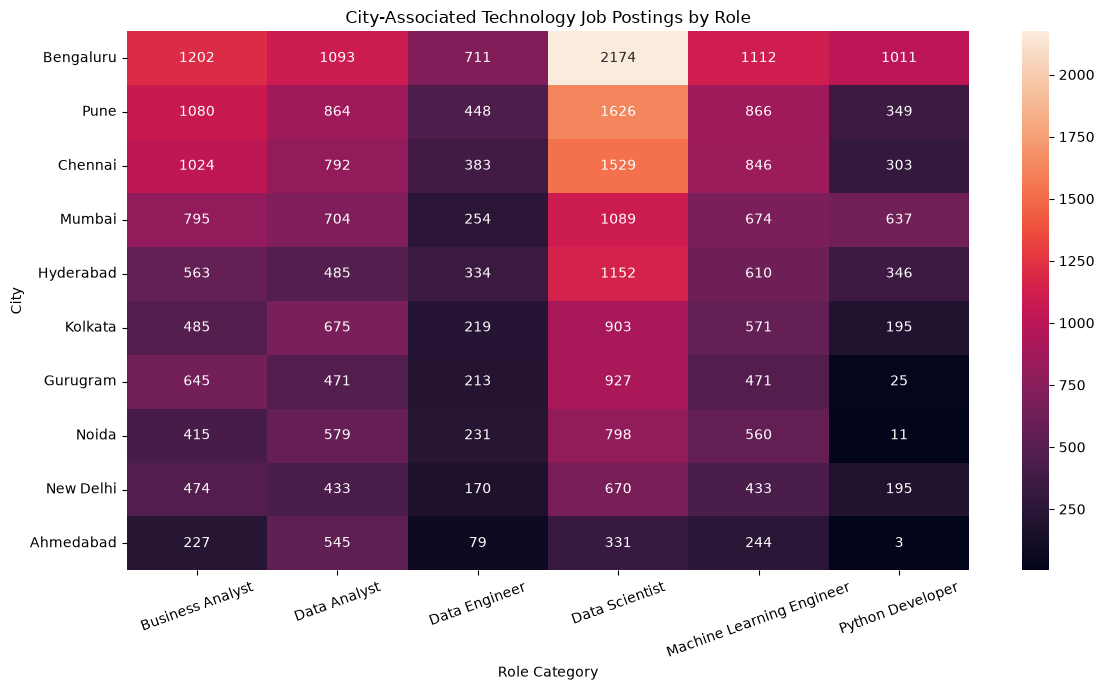

In [318]:
import seaborn as sns
plt.figure(figsize=(12, 7))

sns.heatmap(
    top_city_role,
    annot=True,
    fmt="d"
)

plt.title("City-Associated Technology Job Postings by Role")
plt.xlabel("Role Category")
plt.ylabel("City")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

**🏢 Business Meaning**

**The dataset suggests that Bengaluru is the strongest technology hiring hub across all six analyzed role categories.**

**More specifically:**

**Bengaluru shows broad-based hiring across Data Science, Analytics, Engineering, ML, and Python roles, indicating a diversified technology employment ecosystem rather than dependence on a single role type.**

**Pune and Chennai also show strong demand representation, particularly for Data Scientist, Business Analyst, and Machine Learning Engineer roles.**

**Mumbai stands out somewhat for Python Developer postings compared with Pune and Chennai.**

**🔎 Key Finding**

**Bengaluru dominates the technology job landscape across all six role categories, with Data Scientist postings showing the highest representation at 2,174.**

# 🎯 Dominant Job Role in Each Major City

## 💻 Step 1 — City-wise role percentage

In [323]:

city_role_percentage = (
    top_city_role
    .div(top_city_role.sum(axis=1), axis=0)
    * 100
)

city_role_percentage.round(2)

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
location_clean,,,,,,
Bengaluru,16.46,14.97,9.74,29.77,15.23,13.84
Pune,20.64,16.51,8.56,31.07,16.55,6.67
Chennai,21.00,16.24,7.85,31.35,17.35,6.21
Mumbai,19.14,16.95,6.12,26.22,16.23,15.34
Hyderabad,16.13,13.90,9.57,33.01,17.48,9.91
Kolkata,15.91,22.15,7.19,29.63,18.73,6.40
Gurugram,23.44,17.11,7.74,33.68,17.11,0.91
Noida,16.00,22.32,8.91,30.76,21.59,0.42
New Delhi,19.96,18.23,7.16,28.21,18.23,8.21


## 📊 Step 2 — Visualization

<Figure size 1200x700 with 0 Axes>

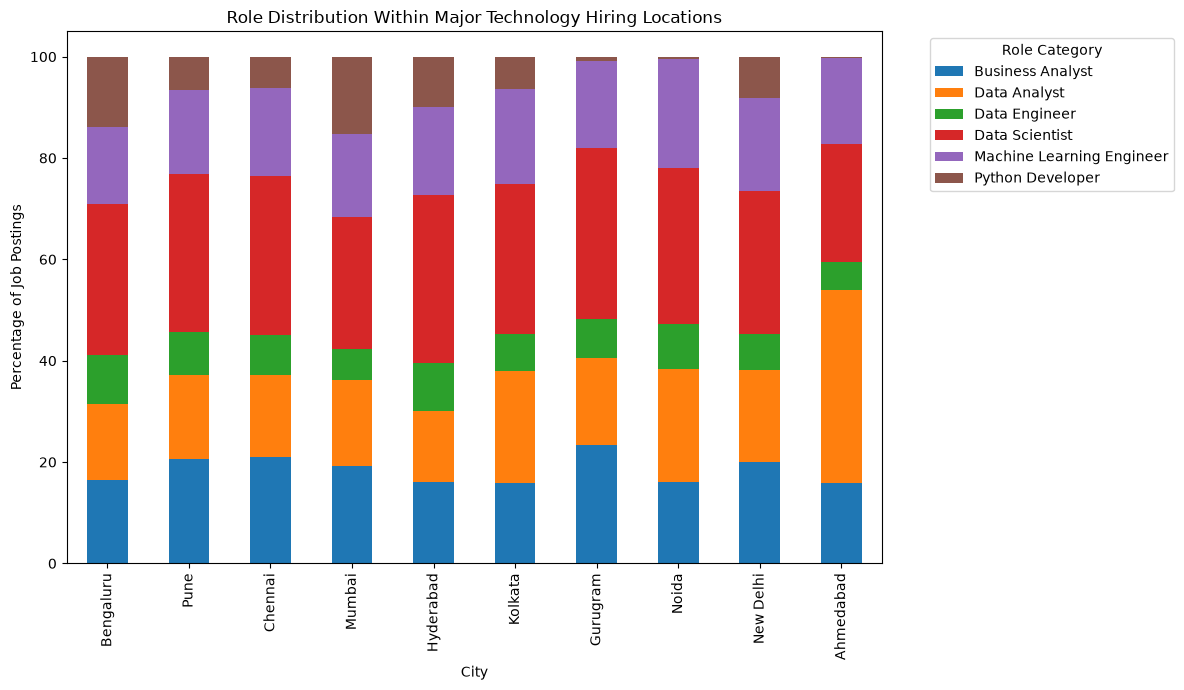

In [325]:
plt.figure(figsize=(12, 7))

city_role_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Role Distribution Within Major Technology Hiring Locations")
plt.xlabel("City")
plt.ylabel("Percentage of Job Postings")
plt.legend(title="Role Category", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

**🏢 Business Meaning**

**The role mix varies considerably by location. Data Scientist roles dominate most major technology hubs, while Ahmedabad and Kolkata show relatively stronger Data Analyst representation. Noida has a comparatively high concentration of Machine Learning Engineer roles, whereas Bengaluru and Mumbai show stronger Python Developer representation.**

# 🎯 Which companies have the highest number of postings across different technology roles?

## 💻 Step 1 — Identify Top companies 

In [331]:
top_companies = (
    df["company_name"]
    .value_counts()
    .head(10)
)

top_companies

company_name
Tata Consultancy Services    653
Accenture                    438
EY                           340
Leading Client               243
Infosys                      209
Capgemini                    195
Photon                       193
Logic Planet                 185
Hexaware Technologies        147
Sparix Global                126
Name: count, dtype: int64

## 💻 Step 2 — Company × Role matrix

In [334]:
company_role = pd.crosstab(
    df["company_name"],
    df["role_category"]
)

top_company_role = company_role.loc[top_companies.index]

top_company_role

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
company_name,,,,,,
Tata Consultancy Services,49,25,59,369,97,54
Accenture,81,138,38,91,82,8
EY,173,75,12,55,18,7
Leading Client,53,56,18,74,22,20
Infosys,16,26,30,53,46,38
Capgemini,38,10,9,62,25,51
Photon,43,26,9,72,13,30
Logic Planet,42,18,34,51,19,21
Hexaware Technologies,45,20,17,43,10,12


**🔎 Key Finding**

**The most important pattern is:**

**Different employers show noticeably different role concentrations: TCS is strongly represented in Data Scientist postings, Accenture in Data Analyst roles, and EY in Business Analyst roles.**

## 📈 Step 3 — Visualization

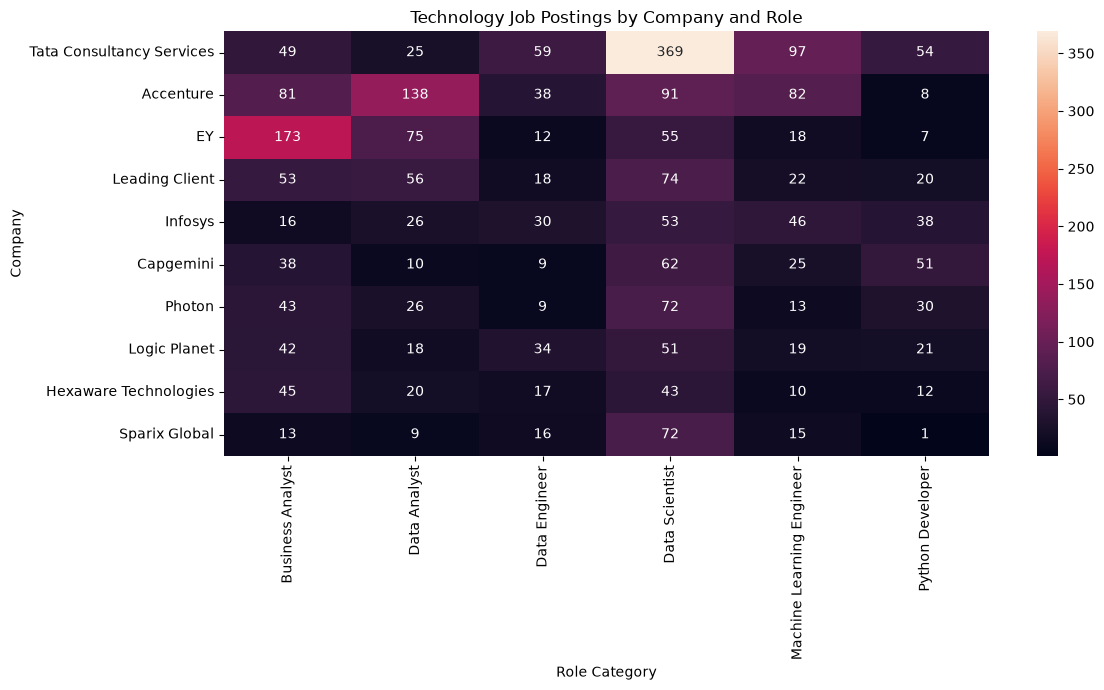

In [339]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    top_company_role,
    annot=True,
    fmt="d"
)

plt.title("Technology Job Postings by Company and Role")
plt.xlabel("Role Category")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

**🏢 Business Meaning**

**The hiring mix varies significantly across major employers. TCS shows strong Data Scientist representation, Accenture has a stronger Data Analyst presence, while EY is particularly concentrated in Business Analyst roles. This indicates that employer-specific role specialization can help candidates target companies according to their desired career path.**

# 🚀 Experience Requirement Analysis

## 💻 Step 1 — Experience Requirement Summary

In [344]:
experience_summary = df[
    ["experience_min_yrs", "experience_max_yrs"]
].describe()

experience_summary

,experience_min_yrs,experience_max_yrs
count,23201.000000,23201.000000
mean,4.135080,7.829059
std,2.933976,3.946834
min,0.000000,0.000000
25%,2.000000,5.000000
50%,4.000000,8.000000
75%,6.000000,10.000000
max,25.000000,31.000000


## 💻 Step 2 — Create a clean experience range

In [347]:
df["experience_range"] = (
    df["experience_max_yrs"] - df["experience_min_yrs"]
)

df[["experience_min_yrs", "experience_max_yrs", "experience_range"]].head()

,experience_min_yrs,experience_max_yrs,experience_range
0,7.0,10.0,3.0
1,4.0,8.0,4.0
2,4.0,9.0,5.0
3,0.0,0.0,0.0
4,5.0,10.0,5.0


In [349]:
df["experience_range"].describe()

count    23201.000000
mean         3.693979
std          1.902395
min        -12.000000
25%          2.000000
50%          4.000000
75%          5.000000
max         29.000000
Name: experience_range, dtype: float64

## 💻 Step 3 — Create valid experience dataset

In [352]:
valid_exp = df[
    df["experience_min_yrs"] <= df["experience_max_yrs"]
].copy()

valid_exp.shape

(23111, 12)

## 🎯 Step 4 — Create Experience Bands

In [355]:
bins = [-1, 2, 5, 10, float("inf")]

labels = [
    "Entry Level (0–2 yrs)",
    "Early/Mid Career (3–5 yrs)",
    "Experienced (6–10 yrs)",
    "Senior (11+ yrs)"
]

valid_exp["experience_band"] = pd.cut(
    valid_exp["experience_min_yrs"],
    bins=bins,
    labels=labels
)

In [357]:
experience_band_counts = (
    valid_exp["experience_band"]
    .value_counts()
    .sort_index()
)

experience_band_counts

experience_band
Entry Level (0–2 yrs)          7134
Early/Mid Career (3–5 yrs)    10112
Experienced (6–10 yrs)         5167
Senior (11+ yrs)                698
Name: count, dtype: int64

In [359]:
experience_band_percentage = (
    experience_band_counts
    / len(valid_exp)
    * 100
)

experience_band_percentage.round(2)

experience_band
Entry Level (0–2 yrs)         30.87
Early/Mid Career (3–5 yrs)    43.75
Experienced (6–10 yrs)        22.36
Senior (11+ yrs)               3.02
Name: count, dtype: float64

**🏢 Business Meaning**

**The dataset indicates a strong concentration of technology opportunities toward entry-level and early/mid-career candidates, with 74.62% of valid postings requiring a maximum of 5 years of minimum experience.**

## 📈 Step 3 — Visualize Experience Distribution

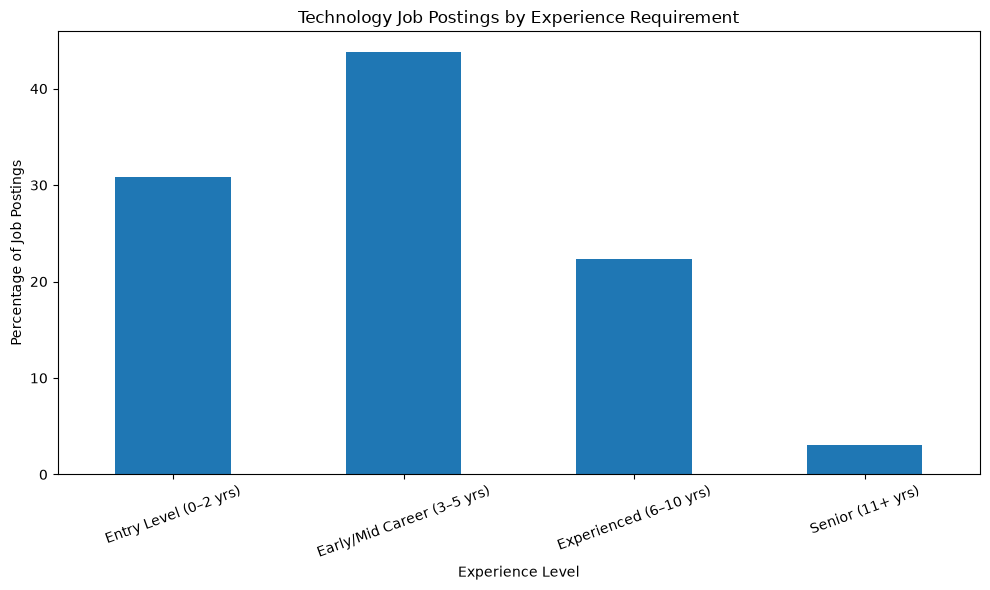

In [363]:
experience_band_percentage.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Technology Job Postings by Experience Requirement")
plt.xlabel("Experience Level")
plt.ylabel("Percentage of Job Postings")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

# 🎯 Which technology roles have the strongest representation of entry-level opportunities?

## 💻 Step 1 — Role × Experience Band table

In [367]:
role_experience = pd.crosstab(
    valid_exp["role_category"],
    valid_exp["experience_band"]
)

role_experience

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
role_category,,,,
Business Analyst,1467,1830,1061,143
Data Analyst,2069,1915,644,93
Data Engineer,362,930,553,70
Data Scientist,1500,3074,1655,184
Machine Learning Engineer,1306,1578,900,202
Python Developer,430,785,354,6


## 💻 Step 2 — Convert to percentages

In [370]:
role_experience_percentage = (
    role_experience
    .div(role_experience.sum(axis=1), axis=0)
    * 100
)

role_experience_percentage.round(2)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
role_category,,,,
Business Analyst,32.59,40.66,23.57,3.18
Data Analyst,43.83,40.56,13.64,1.97
Data Engineer,18.90,48.56,28.88,3.66
Data Scientist,23.39,47.93,25.81,2.87
Machine Learning Engineer,32.76,39.59,22.58,5.07
Python Developer,27.30,49.84,22.48,0.38


**🔎 Key Findings**

**1. Data Analyst has the strongest entry-level representation.
43.83% of Data Analyst postings fall into the 0–2 years minimum-experience band. For someone targeting Data Analyst roles, this is an encouraging signal from this dataset.**

**2. Data Engineer is relatively experience-heavy.
Only 18.90% are entry-level, while 28.88% require 6–10 years. This suggests employers in this dataset are more likely to seek candidates with prior technical experience.**

**3. Data Scientist is mainly an early/mid-career role.
47.93% fall in the 3–5 years band, followed by 25.81% in 6–10 years.**

**4. Machine Learning Engineer has the highest senior-level share.
5.07% of ML Engineer postings have minimum experience of 11+ years, higher than every other role.**

**5. Python Developer is heavily concentrated in 3–5 years.
49.84% are in the Early/Mid Career band, while only 0.38% are Senior.**

## 📊 Step 3 — Visualization

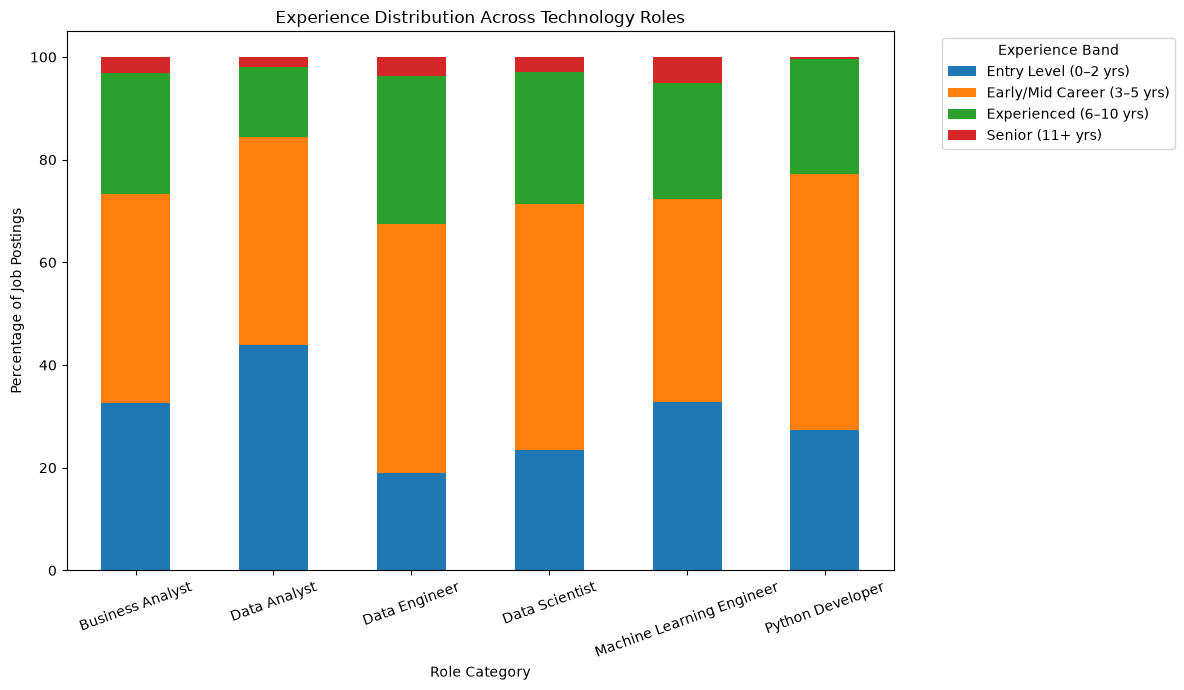

In [374]:
role_experience_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Experience Distribution Across Technology Roles")
plt.xlabel("Role Category")
plt.ylabel("Percentage of Job Postings")

plt.legend(
    title="Experience Band",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**🚀Conclusion**

**Experience requirements vary significantly by role: Data Analyst has the highest entry-level representation, while Data Engineer and Data Scientist are more concentrated in early-to-mid and experienced bands.**

# 🎯 Which companies are hiring candidates at different experience levels?

## Step 1 — Company × Experience Band

In [379]:
company_experience = pd.crosstab(
    valid_exp["company_name"],
    valid_exp["experience_band"]
)

top_company_experience = company_experience.loc[
    top_companies.index
]

top_company_experience

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
company_name,,,,
Tata Consultancy Services,18,326,231,10
Accenture,98,237,59,44
EY,75,186,70,9
Leading Client,41,119,76,7
Infosys,25,153,29,2
Capgemini,29,95,65,5
Photon,23,92,73,5
Logic Planet,31,102,51,1
Hexaware Technologies,22,49,59,17


## Step 2 — Percentage

In [382]:
company_experience_percentage = (
    top_company_experience
    .div(top_company_experience.sum(axis=1), axis=0)
    * 100
)

company_experience_percentage.round(2)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
company_name,,,,
Tata Consultancy Services,3.08,55.73,39.49,1.71
Accenture,22.37,54.11,13.47,10.05
EY,22.06,54.71,20.59,2.65
Leading Client,16.87,48.97,31.28,2.88
Infosys,11.96,73.21,13.88,0.96
Capgemini,14.95,48.97,33.51,2.58
Photon,11.92,47.67,37.82,2.59
Logic Planet,16.76,55.14,27.57,0.54
Hexaware Technologies,14.97,33.33,40.14,11.56


**📊 Explanation & Insight**

#### Tata Consultancy Services (TCS)
Only 3.08% of postings are entry-level, while 55.73% are Early/Mid Career and 39.49% are Experienced.
➡️ In this dataset, TCS hiring is strongly concentrated on candidates with 3–10 years of minimum experience.

#### Accenture
Has 22.37% Entry Level, 54.11% Early/Mid, and 10.05% Senior.
➡️ Compared with TCS, Accenture has a much stronger entry-level representation and also the highest senior-level share among these companies except Hexaware.

#### EY
22.06% Entry Level and 54.71% Early/Mid Career.
➡️ Hiring is primarily concentrated around 3–5 years, with a meaningful entry-level segment.

#### Infosys
A very strong 73.21% Early/Mid Career concentration and only 11.96% Entry Level.
➡️ Infosys is particularly concentrated in the 3–5 year experience band in this dataset.

#### Capgemini
Has 33.51% Experienced postings and 48.97% Early/Mid.
➡️ Relatively more experienced-oriented than Accenture/EY.

#### Photon
37.82% Experienced and 47.67% Early/Mid.
➡️ Hiring is concentrated strongly in 3–10 years.

#### Hexaware Technologies
This one stands out: 40.14% Experienced and 11.56% Senior.
➡️ Among the top 10 companies, Hexaware has a particularly strong experienced/senior hiring profile.

#### Sparix Global
41.27% Experienced, the highest Experienced share among these companies.
➡️ Its hiring mix is strongly tilted toward candidates with 6–10 years of minimum experience.


# 📈 Visualization

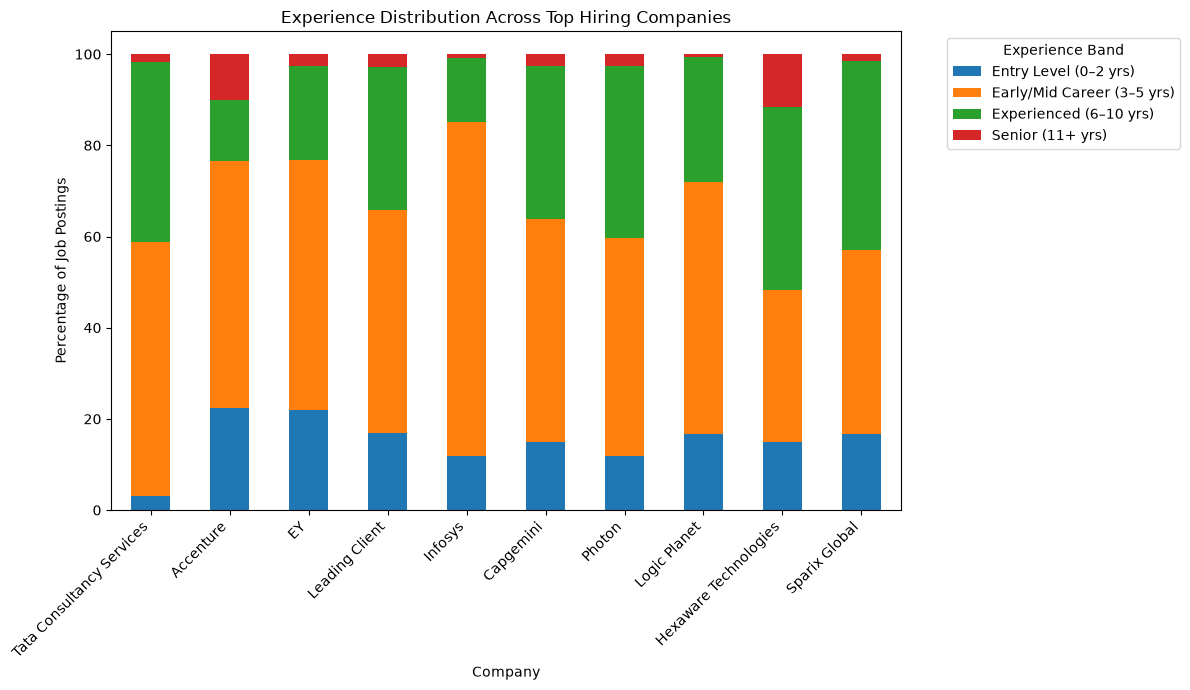

In [386]:
company_experience_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Experience Distribution Across Top Hiring Companies")
plt.xlabel("Company")
plt.ylabel("Percentage of Job Postings")

plt.legend(
    title="Experience Band",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**⭐ 
The experience profile varies significantly across major employers. While some companies show stronger entry-level representation, others are heavily concentrated in early/mid-career and experienced hiring. This indicates that candidate targeting should consider not only the role but also the experience profile associated with each employer.**

# 🎯Do highly rated companies also have higher hiring volume in this dataset?

## Step 1 — Rating-wise hiring volume

In [391]:
rating_hiring = (
    df.groupby("company_rating")
      .size()
      .sort_index()
)

rating_hiring

company_rating
1.0      42
1.1       7
1.2      11
1.3       9
1.4      19
1.5      27
1.6      41
1.7      30
1.8      26
1.9      40
2.0      68
2.1      57
2.2      83
2.3     104
2.4     131
2.5     132
2.6     154
2.7     268
2.8     436
2.9     336
3.0     383
3.1     620
3.2     745
3.3    1604
3.4    1423
3.5    1086
3.6    7120
3.7    1672
3.8    1237
3.9    1111
4.0    1067
4.1     903
4.2     472
4.3     301
4.4     379
4.5     241
4.6     139
4.7     146
4.8      89
4.9     142
5.0     300
dtype: int64

## Step 2 — Percentage 

In [394]:
rating_percentage = (
    rating_hiring / len(df) * 100
)

rating_percentage.round(2)

company_rating
1.0     0.18
1.1     0.03
1.2     0.05
1.3     0.04
1.4     0.08
1.5     0.12
1.6     0.18
1.7     0.13
1.8     0.11
1.9     0.17
2.0     0.29
2.1     0.25
2.2     0.36
2.3     0.45
2.4     0.56
2.5     0.57
2.6     0.66
2.7     1.16
2.8     1.88
2.9     1.45
3.0     1.65
3.1     2.67
3.2     3.21
3.3     6.91
3.4     6.13
3.5     4.68
3.6    30.69
3.7     7.21
3.8     5.33
3.9     4.79
4.0     4.60
4.1     3.89
4.2     2.03
4.3     1.30
4.4     1.63
4.5     1.04
4.6     0.60
4.7     0.63
4.8     0.38
4.9     0.61
5.0     1.29
dtype: float64

# 🎯 Is there a relationship between company rating and hiring volume per company?

## Step 1 — Calculate postings per company + rating

In [398]:
company_rating_analysis = (
    df.groupby(["company_name", "company_rating"])
      .size()
      .reset_index(name="job_postings")
)

company_rating_analysis.head()

,company_name,company_rating,job_postings
0,-,3.6,1
1,.,3.6,2
2,10decoders,2.4,5
3,123 Of Ai,3.6,1
4,1Point1,3.5,1


## Step 2 — Compare rating groups

In [401]:
rating_vs_hiring = (
    company_rating_analysis
    .groupby("company_rating")["job_postings"]
    .mean()
    .reset_index()
)

rating_vs_hiring

,company_rating,job_postings
0,1.0,1.235294
1,1.1,1.750000
2,1.2,1.833333
3,1.3,1.500000
4,1.4,1.900000
5,1.5,1.588235
6,1.6,2.562500
7,1.7,1.111111
8,1.8,1.181818
9,1.9,1.538462


# 📈 Visualization

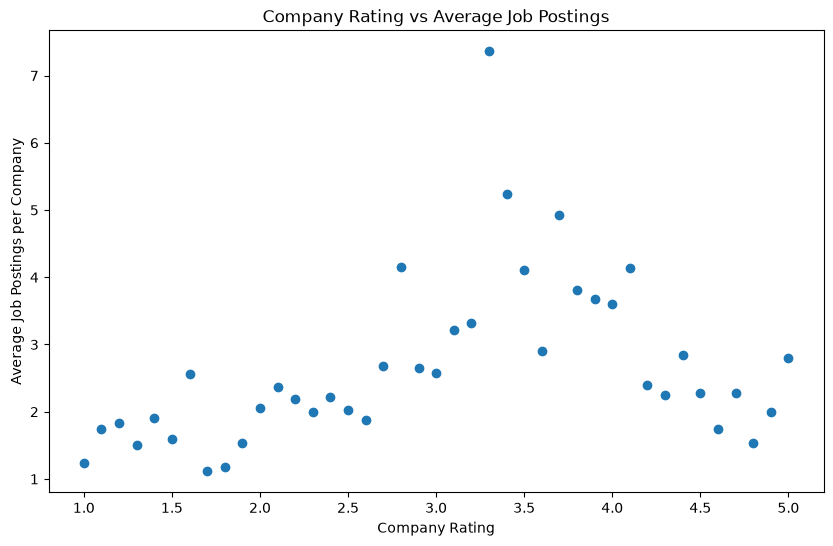

In [404]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rating_vs_hiring["company_rating"],
    rating_vs_hiring["job_postings"]
)

plt.title("Company Rating vs Average Job Postings")
plt.xlabel("Company Rating")
plt.ylabel("Average Job Postings per Company")

plt.show()

# 🎯 Which major Indian locations have relatively more entry-level vs experienced technology job opportunities?

## Step 1 — Location + Experience

In [408]:
location_experience = valid_exp[
    ["location_clean", "experience_band"]
].explode("location_clean")

location_experience["location_clean"] = (
    location_experience["location_clean"].str.strip()
)

## Step 2 — Select Top 10 cities 

In [411]:
top_cities_exp = (
    city_counts
    .drop("Remote", errors="ignore")
    .head(10)
    .index
)

## Step 3 — Cross-tabulation

In [414]:
location_experience_counts = pd.crosstab(
    location_experience["location_clean"],
    location_experience["experience_band"]
)

top_location_experience = location_experience_counts.loc[
    top_cities_exp
]

top_location_experience

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
location_clean,,,,
Bengaluru,1746,3333,2001,202
Pune,1395,2337,1345,142
Chennai,1310,2084,1310,153
Mumbai,1566,1809,677,98
Hyderabad,904,1528,967,81
Kolkata,1150,1249,553,74
Gurugram,820,1228,603,98
Noida,840,1058,592,102
New Delhi,934,1005,392,39


## Step 4 — Percentage

In [417]:
location_experience_percentage = (
    top_location_experience
    .div(top_location_experience.sum(axis=1), axis=0)
    * 100
)

location_experience_percentage.round(2)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
location_clean,,,,
Bengaluru,23.98,45.77,27.48,2.77
Pune,26.73,44.78,25.77,2.72
Chennai,26.97,42.91,26.97,3.15
Mumbai,37.73,43.59,16.31,2.36
Hyderabad,25.98,43.91,27.79,2.33
Kolkata,38.00,41.28,18.27,2.45
Gurugram,29.83,44.67,21.94,3.56
Noida,32.41,40.82,22.84,3.94
New Delhi,39.41,42.41,16.54,1.65


**🏢 
From a candidate strategy perspective:**

**Ahmedabad, New Delhi, Kolkata and Mumbai show relatively stronger entry-level representation, while Bengaluru and Hyderabad show a relatively larger experienced-job mix**

# 📈 Visualization

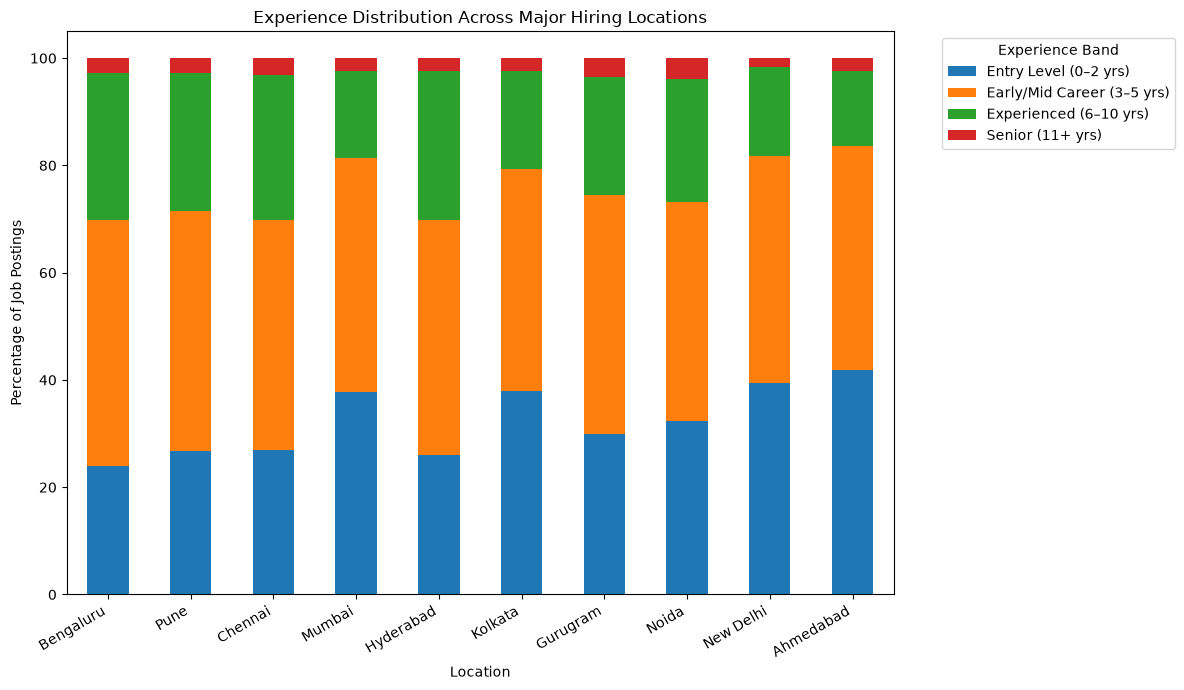

In [421]:
location_experience_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Experience Distribution Across Major Hiring Locations")
plt.xlabel("Location")
plt.ylabel("Percentage of Job Postings")

plt.legend(
    title="Experience Band",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 🔎 Analysis — Data Analyst Opportunities by Location & Experience

## 💻 Step 1 — Filter Data Analyst postings

In [425]:
data_analyst = valid_exp[
    valid_exp["role_category"] == "Data Analyst"
].copy()

## 💻 Step 2 — Expand Locations into Individual City-Level Data

In [428]:
da_location = data_analyst[
    ["location_clean", "experience_band"]
].explode("location_clean")

da_location["location_clean"] = (
    da_location["location_clean"].str.strip()
)

## 💻 Step 3 — Top 10 locations 

In [431]:
top_da_cities = (
    da_location["location_clean"]
    .value_counts()
    .drop("Remote", errors="ignore")
    .head(10)
    .index
)

## 💻 Step 4 — Find Experience distribution 

In [434]:
da_location_experience = pd.crosstab(
    da_location["location_clean"],
    da_location["experience_band"]
)

top_da_location_experience = da_location_experience.loc[
    top_da_cities
]

## 💻 Step 5 — Percentage 

In [437]:
da_location_experience_percentage = (
    top_da_location_experience
    .div(top_da_location_experience.sum(axis=1), axis=0)
    * 100
)

da_location_experience_percentage.round(2)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
location_clean,,,,
Bengaluru,37.18,43.32,17.58,1.92
Pune,39.53,40.93,17.91,1.63
Chennai,40.33,40.46,17.45,1.77
Mumbai,47.94,40.40,10.67,1.00
Kolkata,52.00,34.07,11.56,2.37
Noida,47.15,37.48,12.95,2.42
Ahmedabad,50.46,39.27,8.99,1.28
Hyderabad,40.82,39.38,17.94,1.86
Gurugram,44.37,41.61,12.31,1.70


**🏢 For a Data Analyst candidate, location strategy can depend on experience level:**

**Entry-level candidate: New Delhi, Kolkata and Ahmedabad show stronger relative entry-level representation.
3–5 years experience: Bengaluru, Gurugram and Pune have strong Early/Mid Career representation.
6–10 years experience: Hyderabad, Pune and Bengaluru have relatively higher experienced-role representation.**

# 📈 Visualization

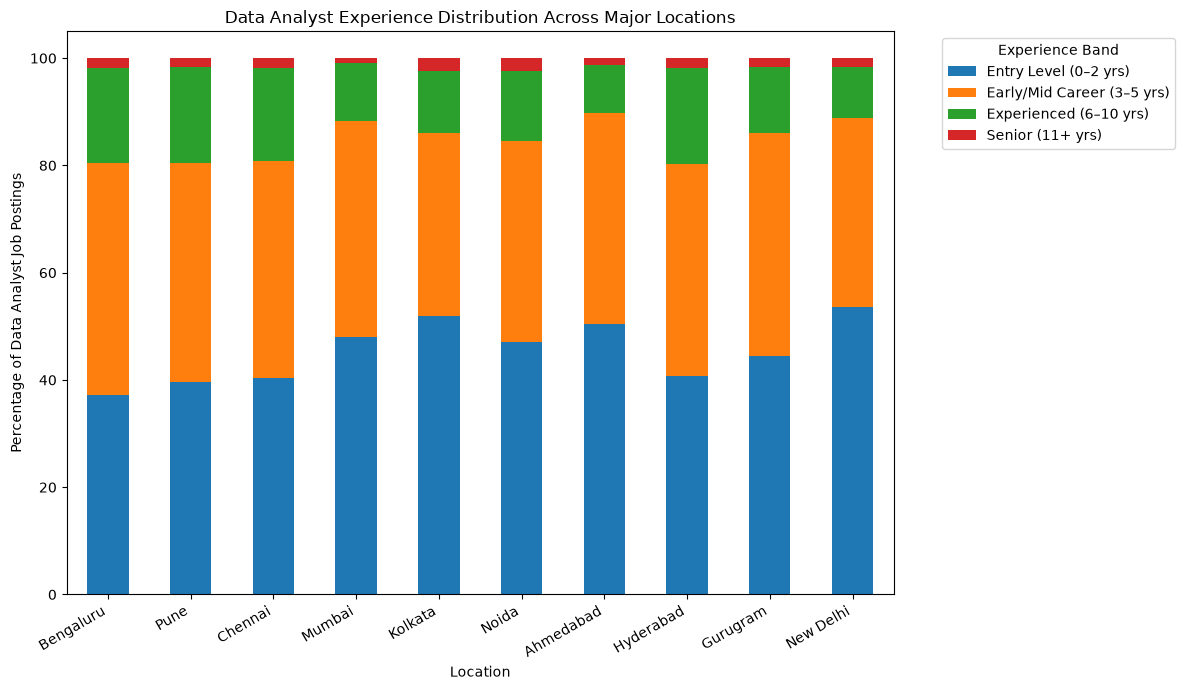

In [441]:
da_location_experience_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Data Analyst Experience Distribution Across Major Locations")
plt.xlabel("Location")
plt.ylabel("Percentage of Data Analyst Job Postings")

plt.legend(
    title="Experience Band",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### 🚀 Conclusion

**Data Analyst opportunities show meaningful geographic differences in experience requirements. New Delhi, Kolkata and Ahmedabad have relatively higher entry-level representation, while Bengaluru, Pune and Hyderabad show a stronger experienced-role mix. This suggests that location can be an important factor when targeting Data Analyst opportunities based on career stage.**

# 🔎 Analysis — Data Analyst: Experience Requirement

## 💻 Step 1 — Experience Distribution

In [446]:
da_experience = (
    data_analyst["experience_band"]
    .value_counts()
    .sort_index()
)

da_experience_percentage = (
    da_experience
    / len(data_analyst)
    * 100
)

da_experience_percentage.round(2)

experience_band
Entry Level (0–2 yrs)         43.83
Early/Mid Career (3–5 yrs)    40.56
Experienced (6–10 yrs)        13.64
Senior (11+ yrs)               1.97
Name: count, dtype: float64

#### 🔎 Key Finding

**Data Analyst hiring in this dataset is strongly concentrated in the 0–5 years experience range, representing 84.39% of postings, while senior roles account for only 1.97%.**

# 📈 Visualization

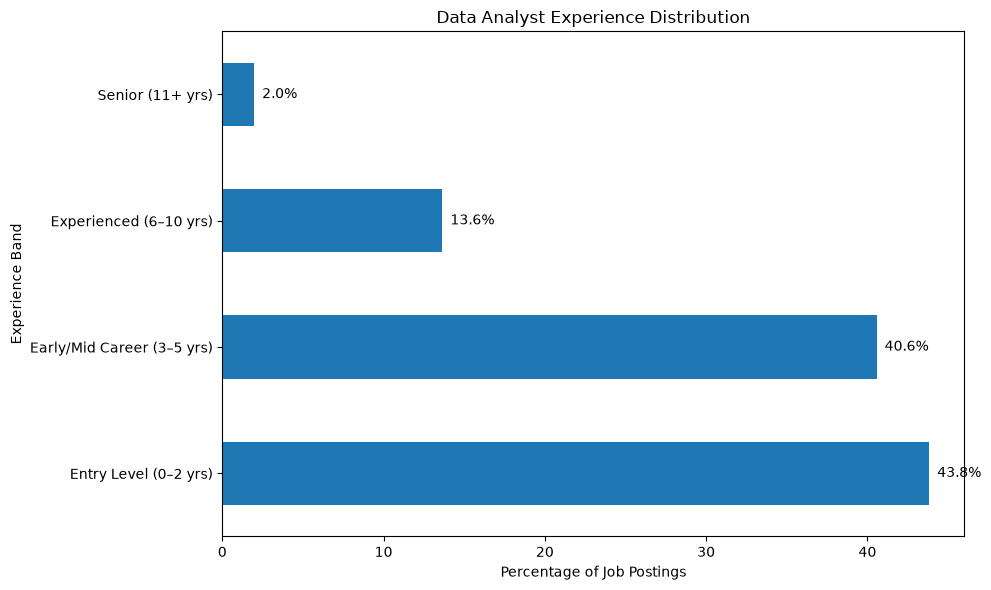

In [450]:
ax = da_experience_percentage.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Data Analyst Experience Distribution")
plt.xlabel("Percentage of Job Postings")
plt.ylabel("Experience Band")

for i, value in enumerate(da_experience_percentage):
    ax.text(value + 0.5, i, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

# Top Companies Hiring for Data Analyst Roles

## 💻 Step 1 — Filter Data Analyst Roles

In [454]:
data_analyst = valid_exp[
    valid_exp["role_category"] == "Data Analyst"
].copy()

## 💻 Step 2 — Find Top Companies

In [457]:
da_company_counts = (
    data_analyst["company_name"]
    .value_counts()
    .head(10)
)

da_company_counts

company_name
Accenture                      138
EY                              75
Leading Client                  56
Crisil                          41
Photon                          26
Infosys                         26
PwC Service Delivery Center     24
Tech Stalwart Solution          23
Tata Consultancy Services       21
Hexaware Technologies           20
Name: count, dtype: int64

**🏢 
Companies should be evaluated by role-specific hiring rather than overall job-posting volume. For Data Analyst candidates, Accenture and EY appear to be stronger targets in this dataset than companies that have higher overall technology hiring volume.**

# Data Analyst Hiring by Company and Experience Level

## 💻 Step 1 — Create Company × Experience Analysis

In [462]:
da_company_experience = pd.crosstab(
    data_analyst["company_name"],
    data_analyst["experience_band"]
)

## 💻 Step 2 — Select the Top Data Analyst Companies

In [465]:
top_da_companies = da_company_counts.index

top_da_company_experience = da_company_experience.loc[
    top_da_companies
]

## 💻 Step 3 — Convert Counts into Percentages

In [468]:
da_company_experience_percentage = (
    top_da_company_experience
    .div(top_da_company_experience.sum(axis=1), axis=0)
    * 100
)

da_company_experience_percentage.round(2)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
company_name,,,,
Accenture,18.12,72.46,4.35,5.07
EY,29.33,54.67,12.00,4.00
Leading Client,50.00,33.93,14.29,1.79
Crisil,48.78,36.59,14.63,0.00
Photon,26.92,61.54,7.69,3.85
Infosys,7.69,88.46,3.85,0.00
PwC Service Delivery Center,33.33,45.83,16.67,4.17
Tech Stalwart Solution,17.39,78.26,4.35,0.00
Tata Consultancy Services,14.29,52.38,33.33,0.00


#### 📊 Explanation

**The company-wise experience distribution shows significant differences in hiring patterns.**

**Leading Client has the highest Entry-Level share among the listed companies at 50.00%.**

**Crisil follows with 48.78% entry-level postings.**

**PwC Service Delivery Center has 33.33% entry-level representation.**

**EY has 29.33% entry-level postings.**

**Accenture, despite having the highest number of Data Analyst postings overall, has only 18.12% Entry-Level and a very high 72.46% Early/Mid-Career share.**

**Infosys is strongly concentrated in Early/Mid Career roles at 88.46%, with only 7.69% Entry-Level.**

**Hexaware Technologies stands out as the most experience-heavy company: 50.00% of its Data Analyst postings fall into the 6–10 years band.**

# 📈 Visualization

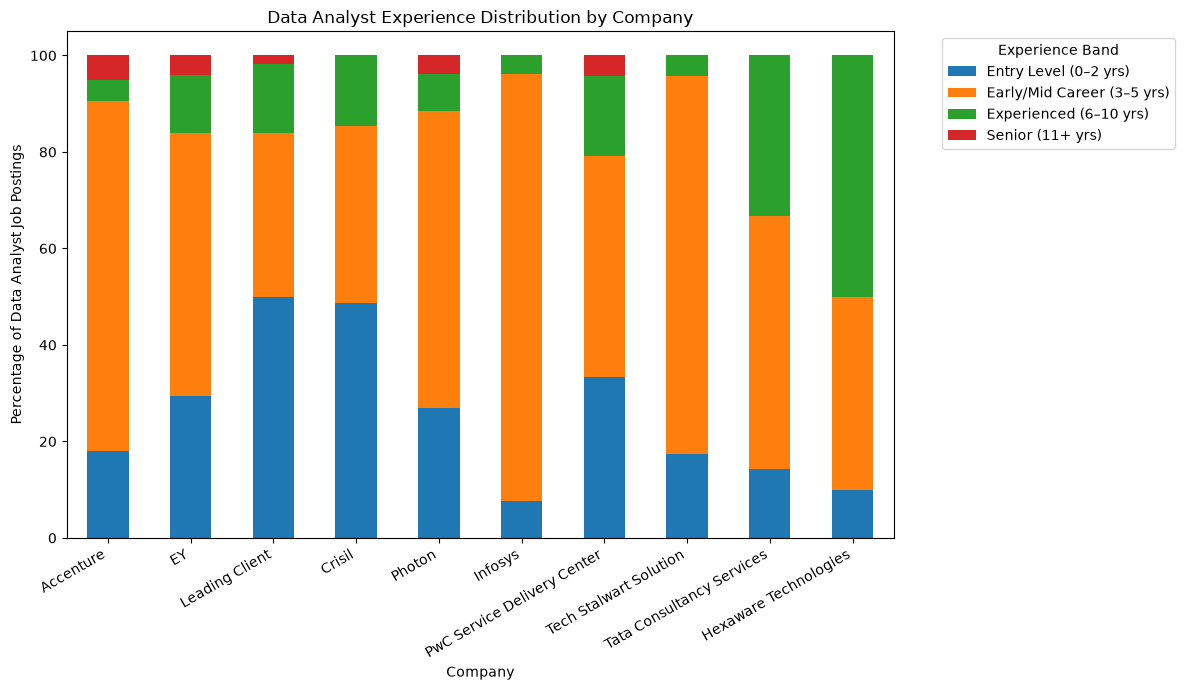

In [472]:
da_company_experience_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Data Analyst Experience Distribution by Company")
plt.xlabel("Company")
plt.ylabel("Percentage of Data Analyst Job Postings")

plt.legend(
    title="Experience Band",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**🚀 
Data Analyst hiring patterns vary substantially across companies. While Accenture has the highest posting volume, its hiring is concentrated in the 3–5 years experience band. In contrast, companies such as Crisil show a higher relative share of entry-level opportunities, while Hexaware has a stronger experienced-hiring profile.**

# Data Analyst Hiring Hotspots by Experience Level

## 💻 Step 1 — Calculate Data Analyst job counts by location

In [477]:
da_location_counts = (
    da_location["location_clean"]
    .value_counts()
    .drop("Remote", errors="ignore")
    .head(10)
)

da_location_counts

location_clean
Bengaluru    1092
Pune          860
Chennai       791
Mumbai        703
Kolkata       675
Noida         579
Ahmedabad     545
Hyderabad     485
Gurugram      471
New Delhi     433
Name: count, dtype: int64

**🏢 
Bengaluru emerges as the strongest location for Data Analyst opportunities in this dataset, while Pune, Chennai and Mumbai also show substantial hiring activity.**

# Data Analyst Hiring by Company and Location

## 💻 Step 1 — Explode multi-location listings

In [482]:
da_company_location_data = data_analyst[
    ["company_name", "location_clean"]
].explode("location_clean")

## 💻 Step 2 — Remove extra spaces

In [487]:
da_company_location_data["location_clean"] = (
    da_company_location_data["location_clean"].str.strip()
)

## 💻 Step 3 —  Create Company × Location matrix

In [490]:
da_company_location = pd.crosstab(
    da_company_location_data["company_name"],
    da_company_location_data["location_clean"]
)

## 💻 Step 4 — Keep Top 10 Data Analyst companies

In [493]:
top_da_company_location = da_company_location.loc[
    top_da_companies
]

## 💻 Step 5 — Keep Top 10 Data Analyst cities

In [496]:
top_da_company_location = top_da_company_location[
    top_da_cities
]

## 💻 Step 5 — Display result

In [499]:
top_da_company_location

location_clean,Bengaluru,Pune,Chennai,Mumbai,Kolkata,Noida,Ahmedabad,Hyderabad,Gurugram,New Delhi
company_name,,,,,,,,,,
Accenture,34,7,2,43,5,6,4,0,26,2
EY,14,6,12,6,7,19,1,0,9,6
Leading Client,21,5,4,12,11,5,18,4,3,0
Crisil,0,21,4,23,2,0,0,0,6,0
Photon,22,22,22,20,20,0,0,20,0,20
Infosys,14,10,12,0,7,0,6,13,0,0
PwC Service Delivery Center,2,0,2,0,14,3,1,5,5,0
Tech Stalwart Solution,13,13,14,13,13,0,0,13,1,13
Tata Consultancy Services,10,4,8,0,5,4,2,6,2,1


**🏢 
This tells us something important for a Data Analyst candidate:**

**Overall company hiring volume ≠ Data Analyst hiring volume.**

**For example, TCS has the highest overall number of technology postings in our dataset, but Accenture is much stronger specifically for Data Analyst postings.**

**So for a candidate targeting Data Analyst roles, company selection should be based on role-specific hiring, not simply the company's total job count.**

# 📈 Create the heatmap

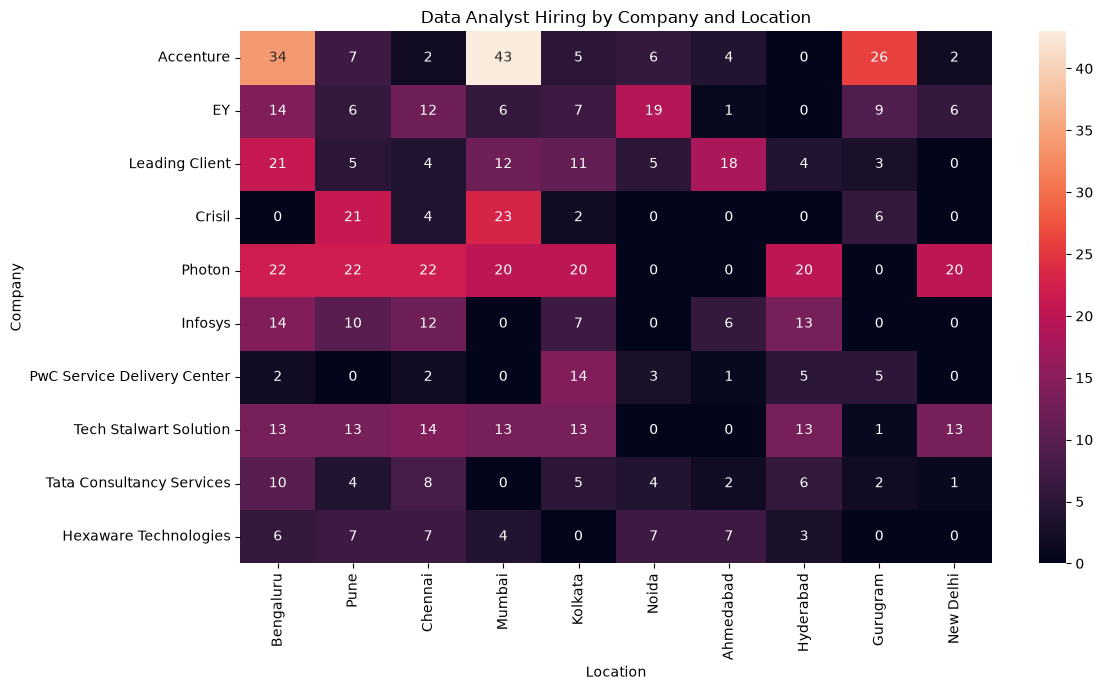

In [398]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    top_da_company_location,
    annot=True,
    fmt="d"
)

plt.title("Data Analyst Hiring by Company and Location")
plt.xlabel("Location")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

**🔎 Key Finding**

**Accenture emerges as the strongest Data Analyst employer among the selected companies, particularly in Mumbai, Bengaluru and Gurugram, while different companies show different geographic hiring patterns.**

# 🎯 Best Company + City for Data Analyst Roles

## Which company-location combinations offer the strongest Data Analyst opportunities?

## 💻 Step 1 — Find the highest company + city combinations

In [510]:
# Convert company-location matrix into a long format
da_company_location_long = (
    top_da_company_location
    .reset_index()
    .melt(
        id_vars="company_name",
        var_name="location",
        value_name="job_postings"
    )
)

# Sort by highest number of postings
top_company_city = (
    da_company_location_long
    .sort_values("job_postings", ascending=False)
    .head(15)
)

top_company_city

,company_name,location,job_postings
30,Accenture,Mumbai,43
0,Accenture,Bengaluru,34
80,Accenture,Gurugram,26
33,Crisil,Mumbai,23
24,Photon,Chennai,22
14,Photon,Pune,22
4,Photon,Bengaluru,22
2,Leading Client,Bengaluru,21
13,Crisil,Pune,21
34,Photon,Mumbai,20


**🎯 Key Finding**

**Accenture has the strongest individual company-location opportunities for Data Analyst roles, led by Mumbai (43), Bengaluru (34), and Gurugram (26).**

**⚠️ Data Quality Observation**

**Photon's repeated values — 22 across several cities and 20 across several others — are unusually uniform. We should flag this rather than treating it as a natural hiring pattern.**

# 🚀 Data Analyst Salary/Experience Opportunity

## 🎯 Which company-location combinations are relatively more accessible to early-career Data Analyst candidates?

In [519]:
# Keep only Top 10 Data Analyst companies
top_da_data = data_analyst[
    data_analyst["company_name"].isin(top_da_companies)
].copy()

# Explode multi-location listings
top_da_data = top_da_data.explode("location_clean")

# Clean spaces
top_da_data["location_clean"] = (
    top_da_data["location_clean"].str.strip()
)

# Keep only Top 10 Data Analyst cities
top_da_data = top_da_data[
    top_da_data["location_clean"].isin(top_da_cities)
]

# Company × Location × Experience
company_city_experience = pd.crosstab(
    [
        top_da_data["company_name"],
        top_da_data["location_clean"]
    ],
    top_da_data["experience_band"]
)

company_city_experience

experience_band                        Entry Level (0–2 yrs)  \
company_name           location_clean                          
Accenture              Ahmedabad                           1   
                       Bengaluru                           6   
                       Chennai                             1   
                       Gurugram                            8   
                       Kolkata                             2   
...                                                      ...   
Tech Stalwart Solution Hyderabad                           3   
                       Kolkata                             3   
                       Mumbai                              3   
                       New Delhi                           3   
                       Pune                                3   

experience_band                        Early/Mid Career (3–5 yrs)  \
company_name           location_clean                               
Accenture              Ahmedabad                                2   
                       Bengaluru                               27   
                       Chennai                                  0   
                       Gurugram                                17   
                       Kolkata                                  0   
...                                                           ...   
Tech Stalwart Solution Hyderabad                                9   
                       Kolkata                                  9   
                       Mumbai                                   9   
                       New Delhi                                9   
                       Pune                                     9   

experience_band                        Experienced (6–10 yrs)  \
company_name           location_clean                           
Accenture              Ahmedabad                            0   
                       Bengaluru                            1   
                       Chennai                              0   
                       Gurugram                             0   
                       Kolkata                              1   
...                                                       ...   
Tech Stalwart Solution Hyderabad                            1   
                       Kolkata                              1   
                       Mumbai                               1   
                       New Delhi                            1   
                       Pune                                 1   

experience_band                        Senior (11+ yrs)  
company_name           location_clean                    
Accenture              Ahmedabad                      1  
                       Bengaluru                      0  
                       Chennai                        1  
                       Gurugram                       1  
                       Kolkata                        2  
...                                                 ...  
Tech Stalwart Solution Hyderabad                      0  
                       Kolkata                        0  
                       Mumbai                         0  
                       New Delhi                      0  
                       Pune                           0  

[76 rows x 4 columns]

# 🎯 Company + City Experience Mix

## Which company-location combinations have a stronger share of entry-level Data Analyst opportunities?

In [523]:
# Convert experience counts into percentages
company_city_experience_pct = (
    company_city_experience
    .div(company_city_experience.sum(axis=1), axis=0)
    * 100
)

company_city_experience_pct.round(2)

experience_band                        Entry Level (0–2 yrs)  \
company_name           location_clean                          
Accenture              Ahmedabad                       25.00   
                       Bengaluru                       17.65   
                       Chennai                         50.00   
                       Gurugram                        30.77   
                       Kolkata                         40.00   
...                                                      ...   
Tech Stalwart Solution Hyderabad                       23.08   
                       Kolkata                         23.08   
                       Mumbai                          23.08   
                       New Delhi                       23.08   
                       Pune                            23.08   

experience_band                        Early/Mid Career (3–5 yrs)  \
company_name           location_clean                               
Accenture              Ahmedabad                            50.00   
                       Bengaluru                            79.41   
                       Chennai                               0.00   
                       Gurugram                             65.38   
                       Kolkata                               0.00   
...                                                           ...   
Tech Stalwart Solution Hyderabad                            69.23   
                       Kolkata                              69.23   
                       Mumbai                               69.23   
                       New Delhi                            69.23   
                       Pune                                 69.23   

experience_band                        Experienced (6–10 yrs)  \
company_name           location_clean                           
Accenture              Ahmedabad                         0.00   
                       Bengaluru                         2.94   
                       Chennai                           0.00   
                       Gurugram                          0.00   
                       Kolkata                          20.00   
...                                                       ...   
Tech Stalwart Solution Hyderabad                         7.69   
                       Kolkata                           7.69   
                       Mumbai                            7.69   
                       New Delhi                         7.69   
                       Pune                              7.69   

experience_band                        Senior (11+ yrs)  
company_name           location_clean                    
Accenture              Ahmedabad                  25.00  
                       Bengaluru                   0.00  
                       Chennai                    50.00  
                       Gurugram                    3.85  
                       Kolkata                    40.00  
...                                                 ...  
Tech Stalwart Solution Hyderabad                   0.00  
                       Kolkata                     0.00  
                       Mumbai                      0.00  
                       New Delhi                   0.00  
                       Pune                        0.00  

[76 rows x 4 columns]

**🎯 Key Finding**

**For Data Analyst roles, early/mid-career candidates (3–5 years minimum experience) appear to form the dominant hiring segment across many company-location combinations, while truly entry-level opportunities are present but generally form a smaller share.**

# 🚀 Best Data Analyst Opportunities for Early-Career Candidates

In [527]:
# Calculate total postings for each company-city combination
company_city_total = (
    company_city_experience
    .sum(axis=1)
    .reset_index(name="total_postings")
)

# Calculate entry-level postings
company_city_total["entry_level_postings"] = (
    company_city_experience["Entry Level (0–2 yrs)"]
    .values
)

# Calculate entry-level percentage
company_city_total["entry_level_percentage"] = (
    company_city_total["entry_level_postings"]
    / company_city_total["total_postings"]
    * 100
)

# Sort by entry-level postings
company_city_total = company_city_total.sort_values(
    ["entry_level_postings", "total_postings"],
    ascending=False
)

company_city_total.head(15)

,company_name,location_clean,total_postings,entry_level_postings,entry_level_percentage
12,Crisil,Mumbai,23,15,65.217391
36,Leading Client,Ahmedabad,18,11,61.111111
3,Accenture,Gurugram,26,8,30.769231
37,Leading Client,Bengaluru,21,8,38.095238
46,Photon,Chennai,22,7,31.818182
13,Crisil,Pune,21,7,33.333333
1,Accenture,Bengaluru,34,6,17.647059
45,Photon,Bengaluru,22,6,27.272727
51,Photon,Pune,22,6,27.272727
47,Photon,Hyderabad,20,6,30.000000


**🏢 Data Analyst hiring accessibility varies by both employer and geography. Candidates should evaluate company-location combinations rather than targeting companies alone.**

# 📈 Visualize the Best Opportunities

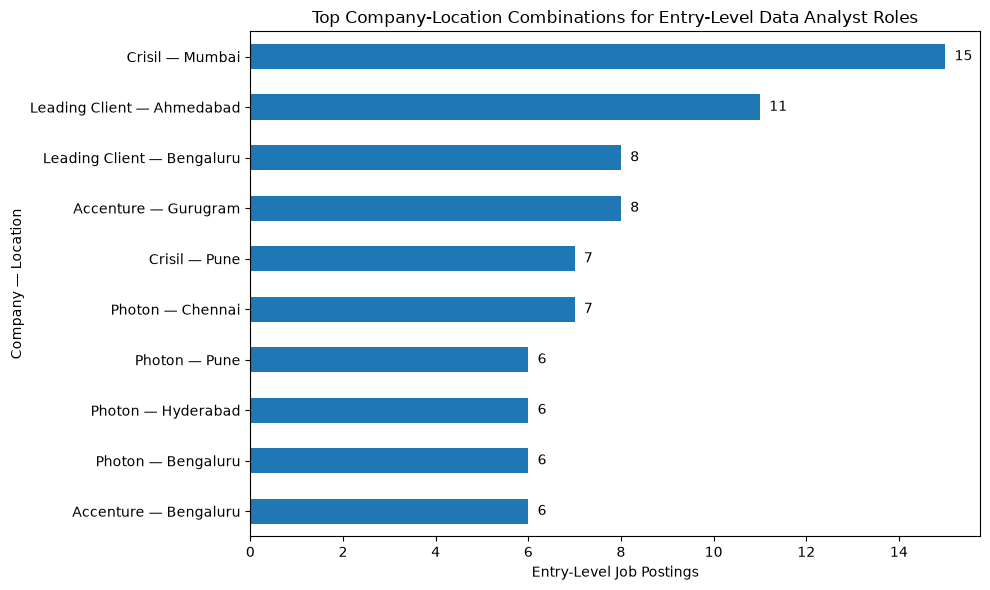

In [531]:
top_entry_level = (
    company_city_total
    .head(10)
    .copy()
)

top_entry_level["company_city"] = (
    top_entry_level["company_name"]
    + " — "
    + top_entry_level["location_clean"]
)

ax = top_entry_level.sort_values(
    "entry_level_postings"
).plot(
    x="company_city",
    y="entry_level_postings",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top Company-Location Combinations for Entry-Level Data Analyst Roles")
plt.xlabel("Entry-Level Job Postings")
plt.ylabel("Company — Location")

for i, value in enumerate(
    top_entry_level.sort_values("entry_level_postings")["entry_level_postings"]
):
    ax.text(value + 0.2, i, str(value), va="center")

plt.tight_layout()
plt.show()

# 🎯 Which Companies Hire Data Analysts at Lower Experience Levels?

In [534]:
# Data Analyst hiring for candidates with 0–5 years experience

da_company_exp = pd.crosstab(
    data_analyst["company_name"],
    data_analyst["experience_band"]
)

# Keep top 10 Data Analyst companies
top_da_company_exp = da_company_exp.loc[
    top_da_companies
]

# Combine Entry + Early/Mid Career
top_da_company_exp["0–5 Years"] = (
    top_da_company_exp["Entry Level (0–2 yrs)"]
    + top_da_company_exp["Early/Mid Career (3–5 yrs)"]
)

# Calculate percentage
top_da_company_exp["0–5 Years %"] = (
    top_da_company_exp["0–5 Years"]
    / top_da_company_exp[
        [
            "Entry Level (0–2 yrs)",
            "Early/Mid Career (3–5 yrs)",
            "Experienced (6–10 yrs)",
            "Senior (11+ yrs)"
        ]
    ].sum(axis=1)
    * 100
)

top_da_company_exp[
    [
        "Entry Level (0–2 yrs)",
        "Early/Mid Career (3–5 yrs)",
        "0–5 Years",
        "0–5 Years %"
    ]
].sort_values(
    "0–5 Years",
    ascending=False
)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),0–5 Years,0–5 Years %
company_name,,,,
Accenture,25,100,125,90.579710
EY,22,41,63,84.000000
Leading Client,28,19,47,83.928571
Crisil,20,15,35,85.365854
Infosys,2,23,25,96.153846
Photon,7,16,23,88.461538
Tech Stalwart Solution,4,18,22,95.652174
PwC Service Delivery Center,8,11,19,79.166667
Tata Consultancy Services,3,11,14,66.666667


**🏢
Most major employers in this dataset have a strong concentration of Data Analyst opportunities requiring up to 5 years of minimum experience, but the accessibility varies considerably by company.**

**Infosys has the highest proportion of Data Analyst postings requiring up to 5 years of minimum experience among the selected companies.**

# 📈 Visualization

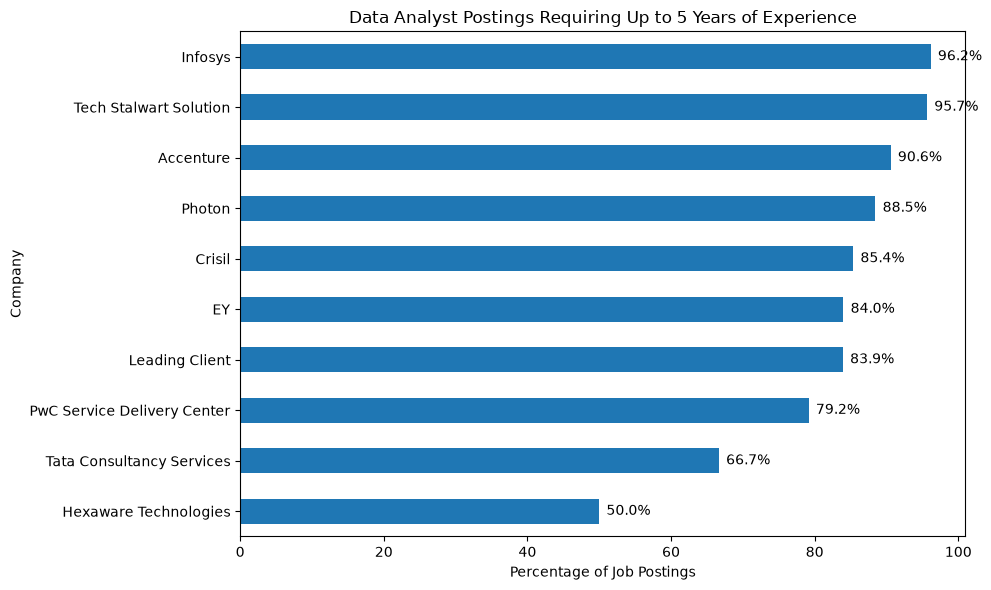

In [539]:
ax = top_da_company_exp.sort_values(
    "0–5 Years %"
)["0–5 Years %"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Data Analyst Postings Requiring Up to 5 Years of Experience")
plt.xlabel("Percentage of Job Postings")
plt.ylabel("Company")

for i, value in enumerate(
    top_da_company_exp.sort_values("0–5 Years %")["0–5 Years %"]
):
    ax.text(value + 1, i, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

***The analysis indicates that most selected companies have a high share of Data Analyst postings requiring up to five years of minimum experience. Infosys and Tech Stalwart Solution show the highest proportions, while Hexaware Technologies and TCS have relatively lower proportions, indicating greater representation of experienced hiring.***

# 🎯 Data Analyst — Role Demand by Location

In [543]:
da_location_counts = (
    da_location["location_clean"]
    .value_counts()
    .drop("Remote", errors="ignore")
    .head(10)
)

da_location_counts

location_clean
Bengaluru    1092
Pune          860
Chennai       791
Mumbai        703
Kolkata       675
Noida         579
Ahmedabad     545
Hyderabad     485
Gurugram      471
New Delhi     433
Name: count, dtype: int64

**🔎 Key Finding**

**Bengaluru is the strongest Data Analyst hiring hotspot in this dataset, with 1,092 city-associated postings, followed by Pune (860) and Chennai (791).**

**🏢 
For a Data Analyst candidate, major technology hubs such as Bengaluru, Pune, Chennai and Mumbai show strong representation of Data Analyst opportunities in this dataset.**

# 📈 Visualization

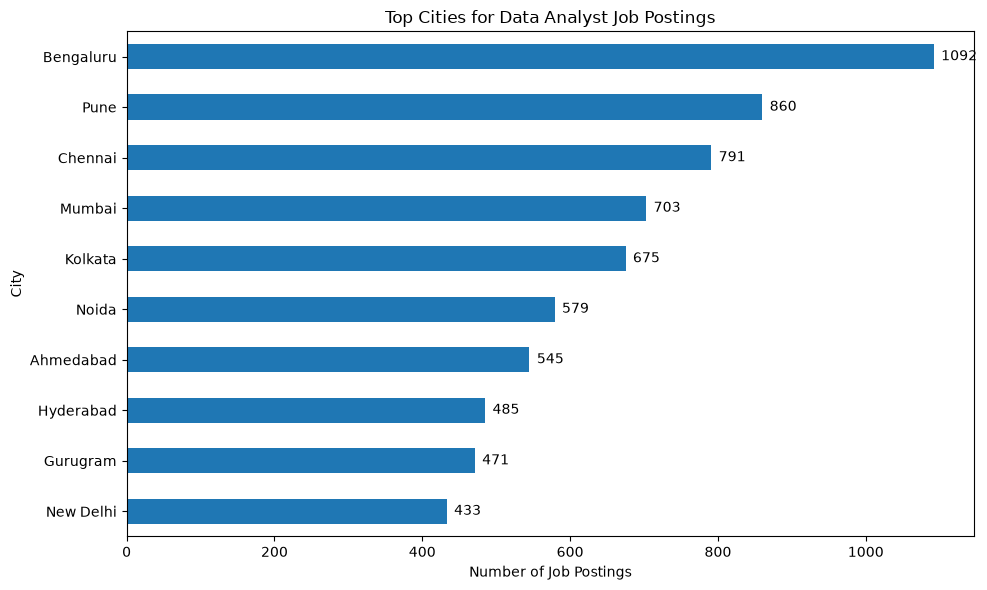

In [549]:
ax = da_location_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top Cities for Data Analyst Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("City")

for i, value in enumerate(da_location_counts.sort_values()):
    ax.text(value + 10, i, str(value), va="center")

plt.tight_layout()
plt.show()

**🏢 
For a candidate targeting Data Analyst roles, Bengaluru, Pune and Chennai appear to be the strongest locations to prioritize based on this dataset.**

# 🌐 Work Mode Analysis — Remote vs Hybrid vs On-site

## 💻 Step 1 — Classify Work Mode

In [587]:
df["work_mode"] = "On-site"

df.loc[
    df["location"].str.contains("Remote", case=False, na=False),
    "work_mode"
] = "Remote"

df.loc[
    df["location"].str.contains("Hybrid", case=False, na=False),
    "work_mode"
] = "Hybrid"

df["work_mode"].value_counts()

work_mode
On-site    18898
Hybrid      2288
Remote      2015
Name: count, dtype: int64

**🔎 Key Finding**

**The Indian tech job postings in this dataset are predominantly on-site, while flexible work arrangements (Hybrid + Remote) form a smaller share of the market.**

# 📈 Visualization

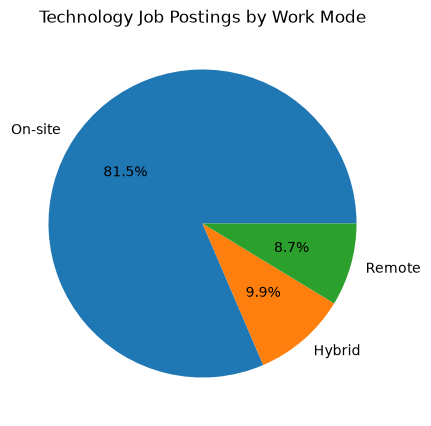

In [591]:
work_mode_counts = df["work_mode"].value_counts()

work_mode_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(5, 5)
)

plt.title("Technology Job Postings by Work Mode")
plt.ylabel("")
plt.show()

**📊 Final Insight**

**On-site work dominates the technology job market in this dataset, representing 81.5% of all postings. Hybrid and Remote opportunities account for 9.9% and 8.7% respectively, showing that flexible work arrangements form a relatively smaller portion of the observed job market.**

# 🌍 Geographic Reach of Technology Roles

## 💻 Step 1 — Count cities for each role

In [596]:
role_city_data = df[
    ["role_category", "location_clean"]
].explode("location_clean")

role_city_data["location_clean"] = (
    role_city_data["location_clean"].str.strip()
)

role_city_data = role_city_data[
    role_city_data["location_clean"] != "Remote"
]

role_city_spread = (
    role_city_data
    .groupby("role_category")["location_clean"]
    .nunique()
    .sort_values(ascending=False)
)

role_city_spread

role_category
Data Analyst                 272
Business Analyst             206
Machine Learning Engineer    176
Data Scientist               160
Data Engineer                 94
Python Developer              75
Name: location_clean, dtype: int64

**🔎 Key Finding**

**Data Analyst has the widest geographic presence in the dataset, appearing across 272 distinct location labels, followed by Business Analyst with 206 and Machine Learning Engineer with 176. Python Developer has the narrowest geographic spread with 75 location labels.**

**🏢 Business Meaning**

**Data Analyst and Business Analyst opportunities appear to have a broader geographic reach, meaning candidates for these roles may have opportunities across a wider range of locations rather than being concentrated only in a few major technology hubs.**

# 📈 Visualization

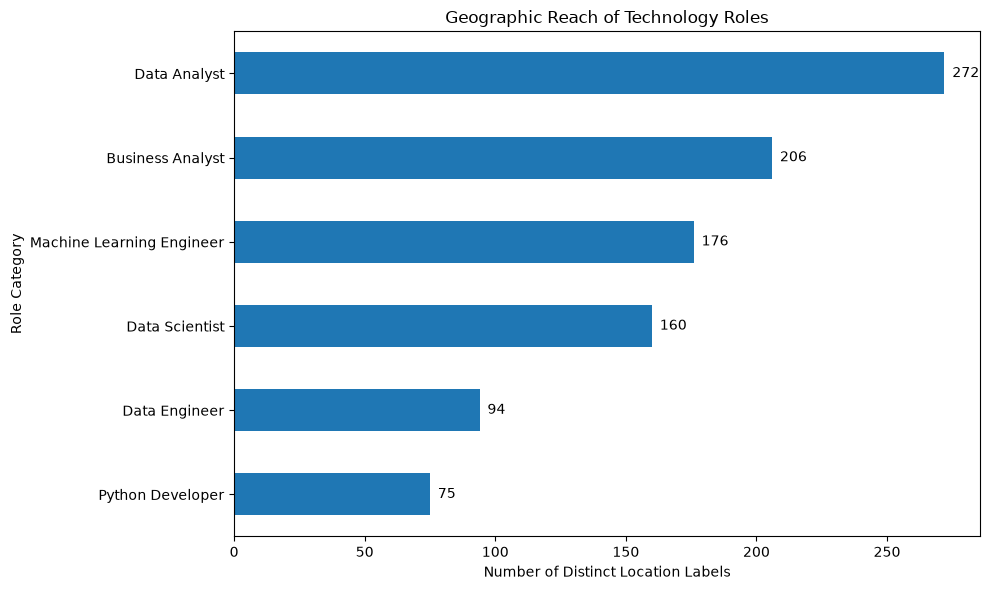

In [601]:
ax = role_city_spread.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Geographic Reach of Technology Roles")
plt.xlabel("Number of Distinct Location Labels")
plt.ylabel("Role Category")

for i, value in enumerate(role_city_spread.sort_values()):
    ax.text(value + 3, i, str(value), va="center")

plt.tight_layout()
plt.show()

# Job Title Diversity by Role

In [604]:
role_title_diversity = (
    df.groupby("role_category")["job_title"]
    .nunique()
    .sort_values(ascending=False)
)

role_title_diversity

role_category
Data Analyst                 3334
Business Analyst             2987
Data Scientist               2982
Machine Learning Engineer    2707
Data Engineer                1249
Python Developer              924
Name: job_title, dtype: int64

**🔎 Key Finding**

**Data Analyst has the highest job-title diversity, with 3,334 distinct titles, followed by Business Analyst and Data Scientist. Python Developer has the lowest title diversity with 924 distinct titles.**

# Hiring Market Concentration

## 💻 Step 1 — Calculate Top 10 Company Share

In [609]:
company_counts = df["company_name"].value_counts()
top_10_jobs = company_counts.head(10).sum()
total_jobs = len(df)
top_10_share = (top_10_jobs / total_jobs) * 100
top_10_share

np.float64(11.762424033446834)

**🔎 Key Finding**

**The technology job market in this dataset is relatively fragmented. The top 10 companies contribute only 11.76% of all job postings, indicating that opportunities are distributed across a large number of employers rather than being concentrated among a few major companies.**

# Work Mode and Experience Analysis

## 💻 Step 1 — Create the Work Mode × Experience table

In [618]:
valid_exp["work_mode"] = df.loc[valid_exp.index, "work_mode"]

In [620]:
workmode_experience = pd.crosstab(
    valid_exp["work_mode"],
    valid_exp["experience_band"])
workmode_experience

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
work_mode,,,,
Hybrid,215,1100,890,79
On-site,6261,8118,3879,554
Remote,658,894,398,65


In [624]:
workmode_experience_percentage = (
    workmode_experience
    .div(workmode_experience.sum(axis=1), axis=0)
    * 100)
workmode_experience_percentage.round(2)

experience_band,Entry Level (0–2 yrs),Early/Mid Career (3–5 yrs),Experienced (6–10 yrs),Senior (11+ yrs)
work_mode,,,,
Hybrid,9.41,48.16,38.97,3.46
On-site,33.28,43.15,20.62,2.94
Remote,32.66,44.37,19.75,3.23


**🔎 Key Finding**

**Hybrid jobs are strongly concentrated toward experienced candidates: 48.16% require 3–5 years and 38.97% require 6–10 years of experience. In comparison, Remote and On-site jobs have a much higher share of Entry-Level opportunities, at 32.66% and 33.28% respectively.**

***Only 9.41% of Hybrid postings fall into the 0–2 years category, compared with 32.66% for Remote and 33.28% for On-site.***

# 📈 Company Rating vs Role Type

## 💻 Step 1 — Create Rating Groups

In [634]:
df["rating_group"] = pd.cut(
    df["company_rating"],
    bins=[0, 3, 3.5, 4, 5],
    labels=["Low", "Medium", "Good", "High"]
)

In [638]:
rating_role = pd.crosstab(
    df["rating_group"],
    df["role_category"])
rating_role

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
rating_group,,,,,,
Low,487,511,185,617,447,157
Medium,1058,955,495,1662,891,417
Good,2386,2624,1022,3303,2089,783
High,574,639,220,873,577,229


## 💻 Step 2 — Calculate Role Distribution %

In [641]:
rating_role_percentage = (
    rating_role
    .div(rating_role.sum(axis=1), axis=0)
    * 100)

rating_role_percentage.round(2)

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
rating_group,,,,,,
Low,20.26,21.26,7.70,25.67,18.59,6.53
Medium,19.31,17.43,9.04,30.34,16.27,7.61
Good,19.55,21.50,8.37,27.06,17.11,6.41
High,18.44,20.53,7.07,28.05,18.54,7.36


**🔎 Key Finding**

**Data Scientist is the largest role category across every company-rating group, ranging from 25.67% in Low-rated companies to 30.34% in Medium-rated companies.**

## Which roles have the widest experience range?

In [647]:
role_experience_range = (
    valid_exp.groupby("role_category")["experience_range"]
    .mean()
    .sort_values(ascending=False))
role_experience_range.round(2)

role_category
Data Engineer                3.94
Data Scientist               3.85
Python Developer             3.79
Machine Learning Engineer    3.77
Business Analyst             3.64
Data Analyst                 3.51
Name: experience_range, dtype: float64

**🔎 Key Finding**

**Data Engineer has the widest average experience range at 3.94 years, followed by Data Scientist at 3.85 years. Data Analyst has the narrowest average range at 3.51 years.**

**Experience-range differences across roles are relatively modest, with Data Engineering showing the widest average range and Data Analytics the narrowest.**

# 📈 Company–Role Specialization

## Which companies are strongly specialized in particular technology roles?

## 💻 Step 1 — Calculate Company–Role Percentage

In [654]:
company_role_percentage = (
    company_role
    .div(company_role.sum(axis=1), axis=0)
    * 100)
top_company_role_percentage = company_role_percentage.loc[
    top_companies.index]
top_company_role_percentage.round(2)

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
company_name,,,,,,
Tata Consultancy Services,7.50,3.83,9.04,56.51,14.85,8.27
Accenture,18.49,31.51,8.68,20.78,18.72,1.83
EY,50.88,22.06,3.53,16.18,5.29,2.06
Leading Client,21.81,23.05,7.41,30.45,9.05,8.23
Infosys,7.66,12.44,14.35,25.36,22.01,18.18
Capgemini,19.49,5.13,4.62,31.79,12.82,26.15
Photon,22.28,13.47,4.66,37.31,6.74,15.54
Logic Planet,22.70,9.73,18.38,27.57,10.27,11.35
Hexaware Technologies,30.61,13.61,11.56,29.25,6.80,8.16


**🔎 Project Finding**

**The analysis reveals clear company-level specialization: EY is strongly Business Analyst-oriented, TCS and Sparix Global are heavily Data Scientist-oriented, while Accenture has the highest Data Analyst share among the top companies.**

# 🚀 Role Demand by Work Mode

## 💻 Step 1 — Role Demand / Work Mode

In [662]:
role_workmode = pd.crosstab(
    df["role_category"],
    df["work_mode"])
role_workmode

work_mode,Hybrid,On-site,Remote
role_category,,,
Business Analyst,304,3969,232
Data Analyst,276,4093,360
Data Engineer,269,1471,182
Data Scientist,824,4989,642
Machine Learning Engineer,388,3034,582
Python Developer,227,1342,17


## 💻 Step 2 — Calculate Work Mode Percentage

In [666]:
role_workmode_percentage = (
    role_workmode
    .div(role_workmode.sum(axis=1), axis=0)
    * 100)
role_workmode_percentage.round(2)

work_mode,Hybrid,On-site,Remote
role_category,,,
Business Analyst,6.75,88.10,5.15
Data Analyst,5.84,86.55,7.61
Data Engineer,14.00,76.53,9.47
Data Scientist,12.77,77.29,9.95
Machine Learning Engineer,9.69,75.77,14.54
Python Developer,14.31,84.62,1.07


**🔎 Project Finding**

**Although On-site jobs dominate across all roles, Machine Learning Engineer has the highest Remote representation (14.54%), while Data Engineer and Data Scientist also show relatively strong flexible-work representation.**

# 🎯 Company Rating × Experience

## 💻 Step 1 — Calculate Average Minimum Experience

In [678]:
valid_exp["rating_group"] = df.loc[valid_exp.index, "rating_group"]

In [680]:
rating_experience = (
    valid_exp.groupby("rating_group")["experience_min_yrs"]
    .mean()
    .sort_index())
rating_experience.round(2)

C:\Users\husan\AppData\Local\Temp\ipykernel_6336\2977205786.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  valid_exp.groupby("rating_group")["experience_min_yrs"]


rating_group
Low       3.59
Medium    4.29
Good      4.20
High      3.77
Name: experience_min_yrs, dtype: float64

**🔎 Project Finding**

**Experience requirements do not increase consistently with company rating; Medium-rated companies show the highest average minimum requirement (4.29 years), while High-rated companies average 3.77 years.**

# 🎯 Seniority in Job Titles

## 💻 Step 1 — Create Seniority Flag

In [685]:
seniority_keywords = (
    "Senior|Sr\\.|Lead|Manager|Head|Director")
df["seniority_level"] = "Non-Senior"
df.loc[
    df["job_title"].str.contains(
        seniority_keywords,
        case=False,
        na=False ),
    "seniority_level"
] = "Senior"

## 💻 Step 2 — Role-wise Seniority

In [688]:
role_seniority = pd.crosstab(
    df["role_category"],
    df["seniority_level"])
role_seniority

seniority_level,Non-Senior,Senior
role_category,,
Business Analyst,3202,1303
Data Analyst,3364,1365
Data Engineer,1522,400
Data Scientist,4564,1891
Machine Learning Engineer,2811,1193
Python Developer,1210,376


## 💻 Step 3 — Calculate Seniority Percentage

In [691]:
role_seniority_percentage = (
    role_seniority
    .div(role_seniority.sum(axis=1), axis=0)
    * 100)
role_seniority_percentage.round(2)

seniority_level,Non-Senior,Senior
role_category,,
Business Analyst,71.08,28.92
Data Analyst,71.14,28.86
Data Engineer,79.19,20.81
Data Scientist,70.70,29.30
Machine Learning Engineer,70.20,29.80
Python Developer,76.29,23.71


**🔎 Key Finding**

**Machine Learning Engineer has the highest share of senior-level job titles at 29.80%, closely followed by Data Scientist at 29.30%. Data Engineer has the lowest senior-title representation at 20.81%.**

# 🚀 Location Diversity by Company

In [695]:
company_location_spread = (
    df[["company_name", "location_clean"]]
    .explode("location_clean"))

company_location_spread["location_clean"] = (
    company_location_spread["location_clean"].str.strip())

company_location_spread = company_location_spread[
    company_location_spread["location_clean"] != "Remote"]

company_location_spread = (
    company_location_spread
    .groupby("company_name")["location_clean"]
    .nunique()
    .sort_values(ascending=False))

company_location_spread.head(10)

company_name
Global Act                    57
Han Digital Solution          39
Logic Planet                  34
Stack Digital                 26
Tata Consultancy Services     25
Axis Max Life Insurance       23
Acme Services                 19
IT Services and Consulting    18
Hexaware Technologies         18
Leading Client                18
Name: location_clean, dtype: int64

**🔎 Key Finding**

**Global Act has the widest geographic footprint in the dataset, appearing across 57 distinct location labels, followed by Han Digital Solution (39) and Logic Planet (34).**

***TCS appears across 25 distinct location labels, while Hexaware Technologies appears across 18.***

# 🚀 Company Hiring Efficiency

In [699]:
company_summary = pd.DataFrame({
    "job_postings": df["company_name"].value_counts(),
    "locations": company_location_spread})

company_summary["postings_per_location"] = (
    company_summary["job_postings"]
    / company_summary["locations"])

company_summary.sort_values(
    "postings_per_location",
    ascending=False
).head(10)

,job_postings,locations,postings_per_location
company_name,,,
Accenture,438,11.0,39.818182
Cloud Counselage,36,1.0,36.000000
Clifyx Technology,56,2.0,28.000000
KLA,27,1.0,27.000000
Tata Consultancy Services,653,25.0,26.120000
EY,340,16.0,21.250000
Codvo,51,3.0,17.000000
Nomura,17,1.0,17.000000
Moris Media,16,1.0,16.000000


**🔎 Key Finding**

**Accenture has the highest posting concentration among the listed companies, with approximately 39.8 postings per location. TCS follows with 26.1 postings per location despite having a much larger geographic footprint of 25 locations.**

# 🚀 Data Quality — Location Standardization

In [703]:
df["location_clean"].explode().str.strip().value_counts().head(30)

location_clean
Bengaluru             7303
Pune                  5233
Chennai               4877
Mumbai                4153
Hyderabad             3490
Kolkata               3048
Gurugram              2752
Noida                 2594
New Delhi             2375
Remote                2015
Ahmedabad             1429
Mumbai (All Areas)     707
Delhi / NCR            554
Navi Mumbai            298
Greater Noida          125
Thane                  104
Nagpur                  92
Nashik                  76
Aurangabad              67
Mumbai Suburban         64
Coimbatore              63
Faridabad               61
Vadodara                57
Ghaziabad               55
Bangalore Rural         55
Bhubaneswar             52
Rajkot                  44
Indore                  44
India                   44
Surat                   43
Name: count, dtype: int64

**🔎 Key Finding**

**The location field contains multiple granularities and geographic variants, meaning raw location labels do not always represent standardized cities or metropolitan areas.**

# 🚀 Create a Standardized City Column

In [707]:
location_counts = (
    df["location_clean"]
    .explode()
    .str.strip()
    .value_counts())

location_counts.tail(30)

location_clean
Chenani                                1
Bengaluru(Kodathi)                     1
Bengaluru(5th Phase JP Nagar)          1
Bengaluru(Old Madras Road)             1
Bengaluru(Bommasandra)                 1
Bengaluru(Electronic City)             1
Panchkula                              1
Haridwar                               1
Bengaluru(Karnataka Layout)            1
Tapi                                   1
Barasat                                1
Malda                                  1
Nadia                                  1
Medinipur                              1
Chennai(Kovilambakkam)                 1
Chennai(Mettukuppam)                   1
Coimbatore(Saravanampatti )            1
Mumbai (All Areas)(Sakinaka)           1
Mumbai (All Areas)(Vikhroli East)      1
Mumbai (All Areas)(Andheri East +1)    1
Mumbai(Goregaon East +3)               1
Solapur                                1
Andheri                                1
Mumbai (All Areas)(Ghatkopar)          1
N

## 💻 Step 1 — Create Standard City

In [712]:
df["standard_city"] = df["location_clean"].apply(
    lambda x: "Bengaluru" if "Bengaluru" in x
    else "Mumbai" if "Mumbai" in x
    else "Chennai" if "Chennai" in x
    else x)

In [714]:
df["standard_city"].value_counts().head(20)

standard_city
Bengaluru                                                                  2734
Chennai                                                                    2666
Mumbai                                                                     2576
[Remote]                                                                   2003
[Gurugram]                                                                 1968
[Noida]                                                                    1877
[Pune]                                                                     1561
[Ahmedabad]                                                                1122
[Kolkata]                                                                   798
[Kolkata,  Mumbai,  New Delhi,  Hyderabad,  Pune,  Chennai,  Bengaluru]     647
[New Delhi]                                                                 357
[Pune,  Kolkata,  Mumbai,  New Delhi,  Hyderabad,  Chennai,  Bengaluru]     198
[New Delhi,  Kolkata,  Mum

In [716]:
location_data = df[["job_id", "location_clean"]].explode("location_clean")
location_data["standard_city"] = location_data["location_clean"].str.strip()
location_data["standard_city"] = location_data["standard_city"].apply(
    lambda x: "Bengaluru" if "Bengaluru" in x
    else "Mumbai" if "Mumbai" in x
    else "Chennai" if "Chennai" in x
    else "Bangalore" if "Bangalore" in x
    else x)
location_data["standard_city"].value_counts().head(20)

standard_city
Bengaluru        7371
Mumbai           5337
Pune             5233
Chennai          4933
Hyderabad        3490
Kolkata          3048
Gurugram         2752
Noida            2594
New Delhi        2375
Remote           2015
Ahmedabad        1429
Delhi / NCR       554
Greater Noida     125
Thane             104
Nagpur             92
Nashik             76
Aurangabad         67
Coimbatore         63
Faridabad          61
Vadodara           57
Name: count, dtype: int64

In [718]:
df[["location", "scraped_city"]].head(10)

,location,scraped_city
0,Bengaluru,Bangalore
1,Bengaluru,Bangalore
2,"Hyderabad, Chennai, Bengaluru",Bangalore
3,"Mumbai, Bengaluru",Bangalore
4,"Pune, Bengaluru",Bangalore
5,"Chennai, Bengaluru",Bangalore
6,"Chennai, Bengaluru",Bangalore
7,Bengaluru,Bangalore
8,Bengaluru,Bangalore
9,Bengaluru,Bangalore


In [720]:
df["scraped_city"].value_counts().head(20)

scraped_city
Bangalore    3685
Mumbai       3368
Chennai      2693
Pune         2557
Delhi        2176
Noida        2147
Remote       1753
Kolkata      1701
Gurgaon      1636
Ahmedabad    1405
Hyderabad      80
Name: count, dtype: int64

In [722]:
pd.crosstab(
    df["scraped_city"],
    df["role_category"]
).head(20)

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
scraped_city,,,,,,
Ahmedabad,219,550,69,318,249,0
Bangalore,626,629,447,851,341,791
Chennai,696,496,184,829,488,0
Delhi,534,426,126,821,269,0
Gurgaon,418,252,179,432,355,0
Hyderabad,14,17,6,20,11,12
Kolkata,246,529,140,473,313,0
Mumbai,597,477,188,803,520,783
Noida,303,530,205,591,518,0


**🔎 Key Finding**

**The dataset contains geographic naming and classification inconsistencies, so city standardization is necessary before making location-based hiring conclusions.**


# 🔎 Job Title Patterns

In [726]:
df[df["role_category"] == "Data Analyst"]["job_title"].value_counts().head(10)

job_title
Data Analyst               155
Business Analyst           118
Senior Data Analyst         60
MIS Executive               34
Executive                   34
Senior Business Analyst     30
Mis Executive               22
Data Engineer               22
Analyst                     22
Senior Analyst              19
Name: count, dtype: int64

In [728]:
for role in df["role_category"].unique():
    print("\n", role)
    print(df[df["role_category"] == role]["job_title"].value_counts().head(5))


 Data Scientist
job_title
Data Scientist          504
Data Engineer           475
Data Analyst            248
Senior Data Engineer    213
Business Analyst        211
Name: count, dtype: int64

 Data Analyst
job_title
Data Analyst           155
Business Analyst       118
Senior Data Analyst     60
MIS Executive           34
Executive               34
Name: count, dtype: int64

 Machine Learning Engineer
job_title
Machine Learning Engineer           131
Artificial Intelligence Engineer     72
AI Engineer                          60
Senior Machine Learning Engineer     45
Data Engineer                        39
Name: count, dtype: int64

 Data Engineer
job_title
Data Engineer           311
Azure Data Engineer      35
Gcp Data Engineer        23
Senior Data Engineer     23
Aws Data Engineer        15
Name: count, dtype: int64

 Business Analyst
job_title
Business Analyst               500
Senior Business Analyst        101
Salesforce Business Analyst     29
Technical Business Analyst     

In [730]:
df["role_category"] == "Data Analyst"

0        False
1        False
2        False
3        False
4        False
         ...  
23196    False
23197    False
23198    False
23199    False
23200    False
Name: role_category, Length: 23201, dtype: bool

In [738]:
df[df["role_category"] == "Data Analyst"]["job_title"].value_counts().head(10)

job_title
Data Analyst               155
Business Analyst           118
Senior Data Analyst         60
MIS Executive               34
Executive                   34
Senior Business Analyst     30
Mis Executive               22
Data Engineer               22
Analyst                     22
Senior Analyst              19
Name: count, dtype: int64

**🔎 Key Finding**

**The biggest observation is that the Data Analyst category is not made up only of Data Analyst titles.**

In [741]:
df["job_title"].str.lower().nunique()

12888

In [743]:
df["job_title"].nunique()

13128

**🎯 Key Finding**

**The dataset contains 240 title variations caused by capitalization differences, indicating minor but measurable text-standardization issues.**

# 🚀 Hiring by Experience Requirement

In [749]:
valid_exp["experience_min_yrs"].value_counts().sort_index().head(15)

experience_min_yrs
0.0     2219
1.0     1963
2.0     2952
3.0     3517
4.0     2607
5.0     3988
6.0     1950
7.0     1307
8.0     1553
9.0      254
10.0     103
11.0      74
12.0     294
13.0      46
14.0      41
Name: count, dtype: int64

**🔎 Key Finding**

**Five years is the most frequently specified minimum experience requirement, followed by 3 and 2 years.**

In [752]:
valid_exp["experience_min_yrs"].value_counts().sort_index()

experience_min_yrs
0.0     2219
1.0     1963
2.0     2952
3.0     3517
4.0     2607
5.0     3988
6.0     1950
7.0     1307
8.0     1553
9.0      254
10.0     103
11.0      74
12.0     294
13.0      46
14.0      41
15.0     178
16.0      16
17.0      10
18.0      15
20.0      22
22.0       1
25.0       1
Name: count, dtype: int64

**🔎 Key Finding**

**The 5-year minimum experience requirement is the single most common requirement, while most postings are concentrated around 2–8 years.**

In [755]:
valid_exp.groupby("role_category")["experience_min_yrs"].mean().sort_values()

role_category
Data Analyst                 3.288922
Python Developer             3.987302
Business Analyst             4.111975
Machine Learning Engineer    4.263673
Data Scientist               4.413535
Data Engineer                4.766580
Name: experience_min_yrs, dtype: float64

# 🔎 Work Mode by Role

In [760]:
work_role = pd.crosstab(
    df["role_category"],
    df["work_mode"])

work_role

work_mode,Hybrid,On-site,Remote
role_category,,,
Business Analyst,304,3969,232
Data Analyst,276,4093,360
Data Engineer,269,1471,182
Data Scientist,824,4989,642
Machine Learning Engineer,388,3034,582
Python Developer,227,1342,17


In [762]:
work_role_pct = work_role.div(
    work_role.sum(axis=1),
    axis=0
) * 100

work_role_pct.round(2)

work_mode,Hybrid,On-site,Remote
role_category,,,
Business Analyst,6.75,88.10,5.15
Data Analyst,5.84,86.55,7.61
Data Engineer,14.00,76.53,9.47
Data Scientist,12.77,77.29,9.95
Machine Learning Engineer,9.69,75.77,14.54
Python Developer,14.31,84.62,1.07


**🏢 
For a candidate searching specifically for flexible work, the dataset suggests:**

**Machine Learning Engineer → strongest Remote representation**

**Python Developer → strongest Hybrid representation**

**Data Analyst → mostly On-site**

# 📈 Visualization

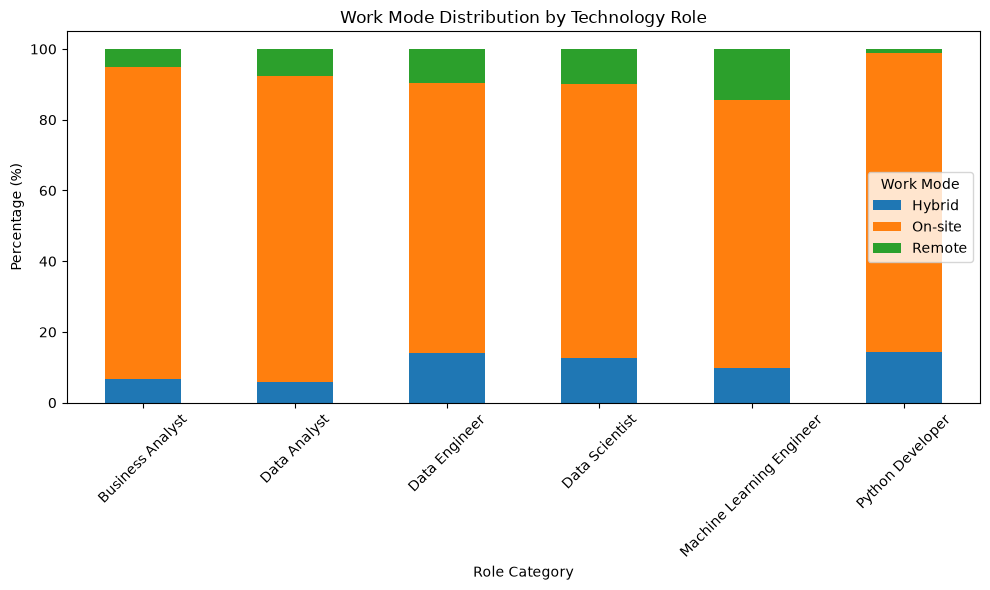

In [767]:
work_role_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Work Mode Distribution by Technology Role")
plt.xlabel("Role Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Work Mode")
plt.tight_layout()
plt.show()

# 🔎 Company Role Diversity

In [770]:
company_role_diversity = (
    df.groupby("company_name")["role_category"]
      .nunique()
      .sort_values(ascending=False))

company_role_diversity.head(15)

company_name
Quarks Technosoft                        6
Exponentia.ai Private Limited            6
Protiviti India                          6
Leading Client                           6
Rarr Technologies                        6
Conneqt                                  6
Luxoft                                   6
Krazy Mantra It                          6
Programming.Com                          6
Logic Planet                             6
Ltimindtree                              6
Lorven Technologies                      6
Tekskills india pvt ltd                  6
Fortune India 500 IT Services Company    6
Premium                                  6
Name: role_category, dtype: int64

**🔎 Key Finding**

**Several companies show hiring across all six technology role categories, indicating a broad hiring portfolio rather than specialization in a single function.**

In [773]:
company_role_diversity.value_counts().sort_index()

role_category
1    4942
2    1204
3     445
4     205
5     124
6      73
Name: count, dtype: int64

**🔎 Key Finding**

**The employer landscape is highly specialized: around 71% of companies represented in the dataset hire within only one of the six role categories.**

# 🚀 Hiring Opportunity by Company Size of Presence

In [777]:
company_role_counts = pd.crosstab(
    df["company_name"],
    df["role_category"])

company_role_counts.head()

role_category,Business Analyst,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Python Developer
company_name,,,,,,
-,0,0,0,1,0,0
.,0,1,0,0,1,0
10decoders,4,0,0,1,0,0
123 Of Ai,0,0,0,1,0,0
1Point1,0,1,0,0,0,0


In [779]:
company_role_counts = pd.crosstab(
    df["company_name"],
    df["role_category"])

company_total = company_role_counts.sum(axis=1)

company_specialization = (
    company_role_counts.max(axis=1) / company_total * 100)

company_specialization.sort_values(ascending=False).head(15)

company_name
xxxxx pvt ltd                100.0
tata consultancy services    100.0
suzva.com                    100.0
spiro                        100.0
smashr global client         100.0
sharpheads                   100.0
sRide                        100.0
rimpac                       100.0
rigbot.com                   100.0
quadric.io                   100.0
protiviti india              100.0
phData                       100.0
7hillsts                     100.0
7dxperts                     100.0
50 Hertz                     100.0
dtype: float64

In [781]:
company_total = company_role_counts.sum(axis=1)

company_specialization = (
    company_role_counts.max(axis=1) / company_total * 100)

company_specialization = company_specialization[
    company_total >= 20]

company_specialization.sort_values(ascending=False).head(15)

company_name
Speechify                      100.000000
Artify Talent Studio            92.000000
Thales                          90.196078
Welo Data                       90.163934
FedEx                           83.333333
Paytm                           82.882883
SWS Smart Working Solutions     80.555556
Highlevel Llc                   77.142857
Airo Digital Labs               75.675676
Info Edge                       74.074074
Prudential                      73.076923
Micro1                          71.428571
Scry Analytics                  70.000000
EXL                             69.230769
Tredence                        66.666667
dtype: float64

# 🚀 Hiring Volume vs Role Specialization

In [784]:
company_analysis = pd.DataFrame({
    "job_postings": company_total,
    "specialization": (
        company_role_counts.max(axis=1) / company_total * 100 )
})

company_analysis = company_analysis[
    company_analysis["job_postings"] >= 20]

company_analysis.head()

,job_postings,specialization
company_name,,
Accenture,438,31.506849
Acenet,23,65.217391
Acme Services,60,36.666667
Acuity Knowledge Partners,20,50.000000
Adani Group,22,63.636364


**🔎 Key Finding**

**Companies with higher specialization percentages tend to have a larger proportion of their hiring concentrated in a single role, while companies such as Accenture show a more diversified role portfolio.**

# 📈 Visualization

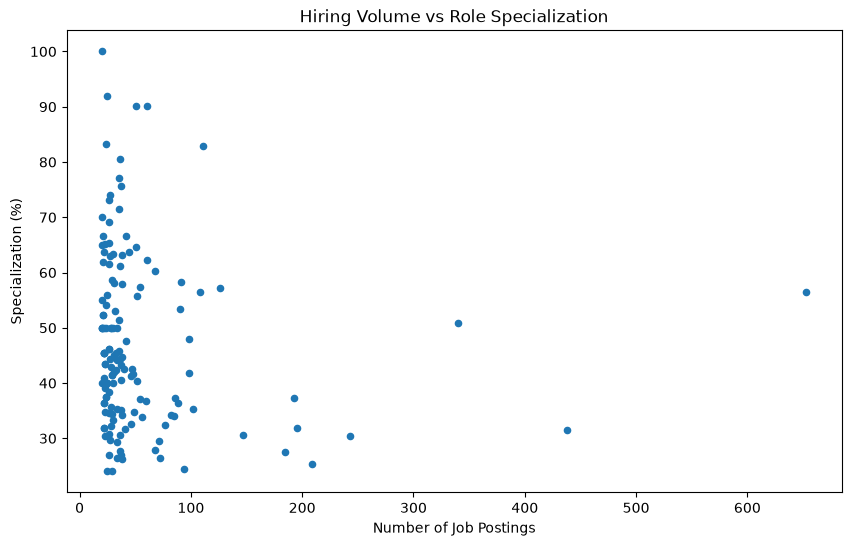

In [790]:
company_analysis.plot(
    kind="scatter",
    x="job_postings",
    y="specialization",
    figsize=(10, 6))

plt.title("Hiring Volume vs Role Specialization")
plt.xlabel("Number of Job Postings")
plt.ylabel("Specialization (%)")
plt.show()

**🔎 Key Finding**

**The dataset shows that high-volume employers tend to have more diversified role portfolios, while many smaller employers show stronger concentration in a single role.**

# 🏁 Final EDA — Business Insights

## 1. Role Demand Pattern
**Data Scientist is the largest role category in the dataset with 6,455 postings (27.8%), followed by Data Analyst and Business Analyst.Business Insight: The dataset has strong representation of data-focused technology roles.**

## 2. Geographic Hiring Hotspots

**After location standardization:**

**Bengaluru → 7,371**

**Mumbai → 5,337**

**Pune → 5,233**

**Chennai → 4,933**

**Hyderabad → 3,490**

**Business Insight: Bengaluru is the strongest hiring location represented in this dataset, with Mumbai and Pune also showing substantial job-location presence.**

## 3. Experience Demand

**The most common minimum experience requirement is:**

**5 years → 3,988 postings**

**The largest concentration is around 2–8 years of minimum experience.**

**Business Insight: The dataset is not dominated by fresher hiring; employers show substantial demand for candidates with prior professional experience.**

## 4. Work Mode

**On-site work dominates all six roles.**

**However:**

**ML Engineer → highest Remote share (14.54%)**

**Python Developer → highest Hybrid share (14.31%)**

**Business Analyst → highest On-site share (88.10%)**

**Business Insight: Work-mode flexibility varies by technology role rather than being uniform across the market.**

## 5. Employer Market Structure

**The top 10 companies account for only 11.76% of all postings.**

**Business Insight: The employer landscape represented by this dataset is relatively fragmented rather than dominated by a small group of companies.**

## 6. Company Role Diversity

**Around 70.7% of companies represented in the dataset appear in only one role category.**

**Only 73 companies appear across all six role categories.**

**Business Insight: Most employers show relatively specialized hiring portfolios, while only a small group demonstrate broad hiring across the six analyzed technology functions.**

## 7. Company Specialization

**The specialization analysis showed that some companies concentrate a large proportion of their postings in one role, while high-volume companies such as Accenture show a more diversified portfolio.**

**Business Insight: Hiring volume and hiring specialization are separate dimensions. A company can have high hiring volume without being highly specialized.**

## 8. Data Quality — One of Your Strongest EDA Points

**The dataset contains several quality issues:**

**Job-title capitalization variations**

**Multi-location postings**

**Location naming variations such as Bengaluru/Bangalore and Gurugram/Gurgaon**

**Role-category and job-title mismatches**

**90 records where extracted minimum experience exceeded maximum experience**

**Generic/anonymized company names such as Leading Client**

**Business Insight: Data preprocessing and validation were necessary before performing reliable hiring analysis.**

# 🚀 Business Recommendations

**Based on the analysis of the 2026 India tech job dataset, the following recommendations can be derived:**

## 1. Focus on Major Technology Hiring Hubs

**Candidates and recruitment teams should prioritize major hiring hubs such as Bengaluru, Mumbai, Pune, and Chennai, which show the highest job-location presence in the analyzed dataset.**

## 2. Build Skills Beyond Fresher-Level Requirements

**Since a large proportion of postings require 2–8 years of minimum experience, candidates should strengthen practical project experience, internships, and industry-relevant skills alongside academic qualifications.**

## 3. Use Role-Specific Job Search Strategies

**Job seekers should search using multiple job-title variations because similar roles may appear under different titles such as Data Analyst, Business Analyst, MIS Executive, and Analyst.**

## 4. Target Companies According to Career Objective

**Candidates seeking broader career opportunities can prioritize employers with diversified role portfolios, while candidates targeting a specific specialization can focus on companies with concentrated hiring in that role.**

## 5. Consider Work-Mode Preferences

**Candidates seeking remote or hybrid opportunities should prioritize roles with relatively higher flexible-work representation, particularly Machine Learning Engineer and Python Developer roles in this dataset.**

## 6. Improve Data Standardization for Recruitment Analytics

**Organizations using job-market data should standardize company names, job titles, locations, and experience fields before performing recruitment analytics to avoid misleading conclusions.**

# 🏁 Conclusion

***This project analyzed the India Tech Job Market using 23,201 job postings to identify hiring patterns across roles, companies, locations, experience levels, and work modes. The analysis showed strong representation of Data Scientist, Data Analyst, and Business Analyst roles, with Bengaluru, Mumbai, Pune, and Chennai emerging as major job-location hubs within the dataset. Experience requirements were concentrated around 2–8 years, while on-site opportunities dominated across all analyzed roles. The analysis also revealed that most companies had relatively specialized role portfolios, whereas a smaller group showed broader hiring across multiple technology functions. Data-quality issues such as location variations, job-title inconsistencies, role-category mismatches, and experience parsing errors were identified and addressed during preprocessing. Overall, the project demonstrates how exploratory data analysis can transform raw job-posting data into actionable insights for candidates, recruiters, and workforce-planning teams.***